# Centralized Learning
## Heart Disease Prediction on Multi-Hospital UCI Dataset

**Research framing.**
Centralized learning (CL) is positioned as a *pooled-data reference comparator* for
federated learning under realistic multi-hospital heterogeneity - not as an
always-available option, and not as a performance upper bound. Four questions drive
the analysis:

1. **Heterogeneity** - How non-IID are the four UCI hospitals in target prevalence,
   feature distribution, and missingness? Section 2.
2. **Preprocessing design** - Does adding categorical features (A->B), a
   validation-tuned decision threshold (B->C), and missingness indicators (C->D)
   change the picture once per-hospital variance is accounted for? Section 5.
3. **Uncertainty** - Do seed-level intervals, which hold the test partition fixed,
   understate the uncertainty that dominates a 920-patient corpus? Sections 8.1
   and 15.1.
4. **Generalisation to unseen hospitals** - Under leave-one-hospital-out (LOHO),
   how does the centralized model behave at a site it never saw? Section 10.

Disparity scalars (worst-hospital AUPRC, gap, Jain Fairness Index) and the SHAP
analyses are computed here as internal diagnostics. The paper reports worst-hospital
AUPRC only.

**Pipeline design principles.**
- Strict train/val/test isolation; identical splits to the FL notebook.
- 10-seed repeated evaluation (seeds 42-132).
- **Primary intervals: patient-level bootstrap** (Section 8.1), resampling test
  patients within each hospital with the validation-tuned threshold held fixed.
  Seed-level t-CIs, Cohen's *d*, and Holm-Bonferroni results are retained
  throughout as the comparator that the bootstrap supersedes, not as the reported
  significance test.
- Five independently drawn held-out test splits (Section 15.1).
- IEEE-ready master summary table at the end.

## 1. Imports & Configuration


In [1]:
import copy
import io
import os
import time
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, confusion_matrix, f1_score, matthews_corrcoef,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy.stats import wilcoxon, t as t_dist
from scipy.spatial.distance import jensenshannon

import shap
import matplotlib.pyplot as plt

# Gradient-boosted tree baseline for tabular data.
import xgboost as xgb
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# Reproducibility & experimental constants
SEEDS       = (42, 52, 62, 72, 82, 92, 102, 112, 122, 132)
TEST_SEED   = 42          # primary external test split (shared with FL notebook)

# --- Uncertainty quantification -------------------------------------------
# Seed-level CIs vary the model seed on a FIXED test partition and therefore
# capture optimisation noise only. The two additions below quantify the
# uncertainty that actually dominates on n=920: which patients land in the
# test set, and which test split we happened to draw.
N_BOOTSTRAP    = 1000     # patient-level bootstrap replicates
BOOTSTRAP_SEED = 7        # RNG seed for the bootstrap itself
TEST_SEEDS     = (42, 202, 303, 404, 505)   # repeated external test splits
MULTI_SPLIT_SEEDS = (42, 52, 62)            # model seeds per repeated split
RUN_MULTI_SPLIT   = True  # set False to skip the (expensive) repeated-split run
TEST_SIZE   = 0.20
VAL_SIZE    = 0.10
BATCH_SIZE  = 32
LR          = 1e-3
EPOCHS      = 200
PATIENCE    = 20
ALPHA       = 0.05        # significance level

NUMERICAL_COLS   = ["age", "trestbps", "chol", "thalch", "oldpeak", "ca"]
CATEGORICAL_COLS = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]
DROP_COLS        = ["id", "num", "dataset"]
TARGET_COL       = "target"
HOSPITAL_COL     = "dataset"


def set_seed(seed: int = 42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
print(f"Seeds: {SEEDS}  (n = {len(SEEDS)})")


Device: cuda
Seeds: (42, 52, 62, 72, 82, 92, 102, 112, 122, 132)  (n = 10)


## 2. Data Loading & Heterogeneity Quantification


In [2]:
df = pd.read_csv("dataset/heart_disease_uci.csv")

# Standardise hidden missing-value markers and remove clinically impossible
# positive-valued measurements before any split/preprocessing is fit.
df = df.replace(["?", "", "NA", "N/A", "null", "None"], np.nan)
CLINICALLY_POSITIVE_COLS = ["chol", "trestbps", "thalch"]
clinical_cleaning_rows = []
for col in CLINICALLY_POSITIVE_COLS:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    invalid = df[col].le(0)
    clinical_cleaning_rows.append({
        "feature": col,
        "n_nonpositive_set_missing": int(invalid.sum()),
    })
    df.loc[invalid, col] = np.nan

df["target"] = (
    pd.to_numeric(df["num"], errors="coerce").fillna(0) > 0
).astype(int)
clinical_cleaning_df = pd.DataFrame(clinical_cleaning_rows)

print(f"Dataset shape: {df.shape}")
print(f"Hospitals: {df[HOSPITAL_COL].unique().tolist()}")
print("\nClinical plausibility cleaning:")
print(clinical_cleaning_df.to_string(index=False))
print()

null_summary = pd.DataFrame({
    "dtype":        df.dtypes,
    "null_count":   df.isnull().sum(),
    "null_percent": df.isnull().mean() * 100
}).sort_values("null_count", ascending=False)
print(null_summary.to_string())
print(f"\nRows with >=1 missing feature: {df.isnull().any(axis=1).sum()}")


Dataset shape: (920, 17)
Hospitals: ['Cleveland', 'Hungary', 'Switzerland', 'VA Long Beach']

Clinical plausibility cleaning:
 feature  n_nonpositive_set_missing
    chol                        172
trestbps                          1
  thalch                          0

            dtype  null_count  null_percent
ca        float64         611     66.413043
thal       object         486     52.826087
slope      object         309     33.586957
chol      float64         202     21.956522
fbs        object          90      9.782609
oldpeak   float64          62      6.739130
trestbps  float64          60      6.521739
exang      object          55      5.978261
thalch    float64          55      5.978261
restecg    object           2      0.217391
id          int64           0      0.000000
dataset    object           0      0.000000
cp         object           0      0.000000
age         int64           0      0.000000
sex        object           0      0.000000
num         int64        

In [3]:
df.groupby('dataset').size()

dataset
Cleveland        304
Hungary          293
Switzerland      123
VA Long Beach    200
dtype: int64

### 2.1 Statistical Heterogeneity

We quantify non-IID-ness across the four hospitals in three complementary ways:
- **Class prevalence divergence** (Jensen-Shannon divergence on P(target)).
- **Feature distribution shift** (per-hospital mean / std for numerical features).
- **Missingness heterogeneity** (per-hospital % missing per feature).

Strong heterogeneity here is the premise for the local-versus-federated comparison,
and the reason per-hospital metrics are reported alongside pooled ones throughout.

In [4]:
hospitals = df[HOSPITAL_COL].unique().tolist()
n_h = len(hospitals)

# Class distribution per hospital
hosp_counts = df.groupby([HOSPITAL_COL, TARGET_COL]).size().unstack(fill_value=0)
hosp_ratio  = hosp_counts.div(hosp_counts.sum(axis=1), axis=0)
print("Class counts per hospital:")
print(hosp_counts.to_string())
print("\nPositive-class prevalence per hospital:")
print(hosp_ratio.round(4).to_string())

# Jensen-Shannon divergence on class distribution
pos_rates = hosp_ratio[1].values
jsd_mat = np.zeros((n_h, n_h))
for i in range(n_h):
    for j in range(n_h):
        p = np.array([pos_rates[i], 1 - pos_rates[i]])
        q = np.array([pos_rates[j], 1 - pos_rates[j]])
        jsd_mat[i, j] = jensenshannon(p, q)

jsd_df = pd.DataFrame(jsd_mat, index=hospitals, columns=hospitals)
upper  = jsd_mat[np.triu_indices_from(jsd_mat, k=1)]
print("\nClass-distribution Jensen-Shannon Divergence matrix:")
print(jsd_df.round(4).to_string())
print(f"\nMean inter-hospital JSD: {upper.mean():.4f}")
print(f"Max  inter-hospital JSD: {upper.max():.4f}")


Class counts per hospital:
target           0    1
dataset                
Cleveland      165  139
Hungary        187  106
Switzerland      8  115
VA Long Beach   51  149

Positive-class prevalence per hospital:
target              0       1
dataset                      
Cleveland      0.5428  0.4572
Hungary        0.6382  0.3618
Switzerland    0.0650  0.9350
VA Long Beach  0.2550  0.7450

Class-distribution Jensen-Shannon Divergence matrix:
               Cleveland  Hungary  Switzerland  VA Long Beach
Cleveland         0.0000   0.0687       0.3861         0.2096
Hungary           0.0687   0.0000       0.4482         0.2763
Switzerland       0.3861   0.4482       0.0000         0.1885
VA Long Beach     0.2096   0.2763       0.1885         0.0000

Mean inter-hospital JSD: 0.2629
Max  inter-hospital JSD: 0.4482


In [5]:
# Feature-distribution shift across hospitals
feat_rows = []
for hosp in hospitals:
    sub = df[df[HOSPITAL_COL] == hosp]
    row = {"hospital": hosp, "n": len(sub),
           "positive_rate": sub[TARGET_COL].mean()}
    for col in NUMERICAL_COLS:
        row[f"{col}_mean"] = sub[col].mean()
        row[f"{col}_std"]  = sub[col].std()
        row[f"{col}_miss"] = sub[col].isnull().mean() * 100
    feat_rows.append(row)

feat_dist_df = pd.DataFrame(feat_rows).set_index("hospital")
print("Feature means per hospital:")
print(feat_dist_df[[f"{c}_mean" for c in NUMERICAL_COLS]].round(2).to_string())
print("\nMissing rates (%) per hospital x feature:")
print(feat_dist_df[[f"{c}_miss" for c in NUMERICAL_COLS]].round(1).to_string())


Feature means per hospital:
               age_mean  trestbps_mean  chol_mean  thalch_mean  oldpeak_mean  ca_mean
hospital                                                                             
Cleveland         54.35         131.68     246.32       149.72          1.04     0.67
Hungary           47.89         132.59     251.29       138.97          0.59     0.00
Switzerland       55.32         130.21        NaN       121.56          0.65     1.60
VA Long Beach     59.35         134.70     239.57       122.80          1.32     0.00

Missing rates (%) per hospital x feature:
               age_miss  trestbps_miss  chol_miss  thalch_miss  oldpeak_miss  ca_miss
hospital                                                                             
Cleveland           0.0            0.0        0.0          0.0           0.0      1.6
Hungary             0.0            0.3        7.8          0.3           0.0     99.0
Switzerland         0.0            1.6      100.0          0.8       

## 3. Helper Functions

Splits, leakage-free preprocessing, model utilities, metrics, fairness, and CIs.


In [6]:
# Split helpers (identical to FL notebook for protocol consistency)
def make_stratify_label(df_in, hospital_col=HOSPITAL_COL, target_col=TARGET_COL):
    return df_in[hospital_col].astype(str) + "__" + df_in[target_col].astype(str)


def create_fixed_external_test_split(df_raw, seed=TEST_SEED, test_size=TEST_SIZE):
    strat = make_stratify_label(df_raw)
    df_tv, df_test = train_test_split(
        df_raw, test_size=test_size, stratify=strat, random_state=seed)
    return df_tv.reset_index(drop=True), df_test.reset_index(drop=True)


def create_inner_train_val_split(df_tv, seed, val_size=VAL_SIZE):
    strat = make_stratify_label(df_tv)
    df_tr, df_val = train_test_split(
        df_tv, test_size=val_size, stratify=strat, random_state=seed)
    return df_tr.reset_index(drop=True), df_val.reset_index(drop=True)


In [7]:
# Feature/threshold settings A / B / C / D / E
# B and C deliberately share the same feature preprocessing; C differs only by
# validation-set decision-threshold tuning. D adds missingness indicators after
# clinical cleaning. E drops likely site-artifact columns as sensitivity analysis.
def _split_xy(df_in):
    y = df_in[TARGET_COL].values
    X = df_in.drop(columns=[TARGET_COL]).copy()
    return X, y


def _force_numeric(X, cols):
    for c in cols:
        if c in X.columns:
            X[c] = pd.to_numeric(X[c], errors="coerce")
    return X


def _preprocess_tabular(df_train, df_val, df_test, numerical_cols,
                        categorical_cols=None, missing_indicator_cols=None,
                        setting="B"):
    categorical_cols = [c for c in (categorical_cols or []) if c in df_train.columns]
    missing_indicator_cols = [
        c for c in (missing_indicator_cols or []) if c in df_train.columns
    ]

    def _extract(d):
        d = d.drop(columns=DROP_COLS, errors="ignore")
        return _split_xy(d)

    X_tr, y_tr = _extract(df_train)
    X_va, y_va = _extract(df_val)
    X_te, y_te = _extract(df_test)
    numerical_cols = [c for c in numerical_cols if c in X_tr.columns]

    X_tr = _force_numeric(X_tr, numerical_cols)
    X_va = _force_numeric(X_va, numerical_cols)
    X_te = _force_numeric(X_te, numerical_cols)

    ind_tr = pd.DataFrame(index=X_tr.index)
    ind_va = pd.DataFrame(index=X_va.index)
    ind_te = pd.DataFrame(index=X_te.index)
    for c in missing_indicator_cols:
        ind_tr[f"{c}_missing"] = X_tr[c].isna().astype(np.float32)
        ind_va[f"{c}_missing"] = X_va[c].isna().astype(np.float32)
        ind_te[f"{c}_missing"] = X_te[c].isna().astype(np.float32)

    num_imp = SimpleImputer(strategy="median", keep_empty_features=True)
    X_tr_n = pd.DataFrame(num_imp.fit_transform(X_tr[numerical_cols]),
                          columns=numerical_cols, index=X_tr.index)
    X_va_n = pd.DataFrame(num_imp.transform(X_va[numerical_cols]),
                          columns=numerical_cols, index=X_va.index)
    X_te_n = pd.DataFrame(num_imp.transform(X_te[numerical_cols]),
                          columns=numerical_cols, index=X_te.index)

    scaler = StandardScaler()
    X_tr_ns = pd.DataFrame(scaler.fit_transform(X_tr_n),
                           columns=numerical_cols, index=X_tr.index)
    X_va_ns = pd.DataFrame(scaler.transform(X_va_n),
                           columns=numerical_cols, index=X_va.index)
    X_te_ns = pd.DataFrame(scaler.transform(X_te_n),
                           columns=numerical_cols, index=X_te.index)

    cat_fill = {}
    if categorical_cols:
        X_tr_c = X_tr[categorical_cols].copy().astype("string")
        X_va_c = X_va[categorical_cols].copy().astype("string")
        X_te_c = X_te[categorical_cols].copy().astype("string")
        for col in categorical_cols:
            mode = X_tr_c[col].mode(dropna=True)
            fv = mode.iloc[0] if len(mode) > 0 else "unknown"
            cat_fill[col] = fv
            X_tr_c[col] = X_tr_c[col].fillna(fv)
            X_va_c[col] = X_va_c[col].fillna(fv)
            X_te_c[col] = X_te_c[col].fillna(fv)
        X_tr_oh = pd.get_dummies(X_tr_c, columns=categorical_cols, drop_first=True)
        X_va_oh = pd.get_dummies(X_va_c, columns=categorical_cols, drop_first=True).reindex(
            columns=X_tr_oh.columns, fill_value=0)
        X_te_oh = pd.get_dummies(X_te_c, columns=categorical_cols, drop_first=True).reindex(
            columns=X_tr_oh.columns, fill_value=0)
    else:
        X_tr_oh = pd.DataFrame(index=X_tr.index)
        X_va_oh = pd.DataFrame(index=X_va.index)
        X_te_oh = pd.DataFrame(index=X_te.index)

    X_tr_f = pd.concat([X_tr_ns, X_tr_oh, ind_tr], axis=1)
    X_va_f = pd.concat([X_va_ns, X_va_oh, ind_va], axis=1)
    X_te_f = pd.concat([X_te_ns, X_te_oh, ind_te], axis=1)

    info = {"setting": setting, "num_imputer": num_imp, "scaler": scaler,
            "cat_fill": cat_fill, "feature_columns": X_tr_f.columns.tolist(),
            "cat_dummy_cols": X_tr_oh.columns.tolist(),
            "missing_indicator_cols": missing_indicator_cols,
            "numerical_cols_used": numerical_cols,
            "categorical_cols_used": categorical_cols}
    return (X_tr_f.to_numpy(np.float32), X_va_f.to_numpy(np.float32),
            X_te_f.to_numpy(np.float32),
            y_tr.astype(np.float32), y_va.astype(np.float32),
            y_te.astype(np.float32), info)


def preprocess_setting_a(df_train, df_val, df_test, keep_hospital=False):
    return _preprocess_tabular(df_train, df_val, df_test,
                               numerical_cols=NUMERICAL_COLS,
                               categorical_cols=[], setting="A")


def preprocess_setting_b(df_train, df_val, df_test):
    return _preprocess_tabular(df_train, df_val, df_test,
                               numerical_cols=NUMERICAL_COLS,
                               categorical_cols=CATEGORICAL_COLS, setting="B")


def preprocess_setting_c(df_train, df_val, df_test):
    X_tr, X_va, X_te, y_tr, y_va, y_te, info = preprocess_setting_b(
        df_train, df_val, df_test)
    info["setting"] = "C"
    return X_tr, X_va, X_te, y_tr, y_va, y_te, info


def preprocess_setting_d(df_train, df_val, df_test):
    return _preprocess_tabular(df_train, df_val, df_test,
                               numerical_cols=NUMERICAL_COLS,
                               categorical_cols=CATEGORICAL_COLS,
                               missing_indicator_cols=NUMERICAL_COLS,
                               setting="D")


def preprocess_setting_e(df_train, df_val, df_test):
    numerical_cols = [c for c in NUMERICAL_COLS if c not in {"chol", "ca"}]
    categorical_cols = [c for c in CATEGORICAL_COLS if c != "thal"]
    return _preprocess_tabular(df_train, df_val, df_test,
                               numerical_cols=numerical_cols,
                               categorical_cols=categorical_cols,
                               missing_indicator_cols=numerical_cols,
                               setting="E")


PREPROCESSORS = {"A": preprocess_setting_a,
                 "B": preprocess_setting_b,
                 "C": preprocess_setting_c,
                 "D": preprocess_setting_d,
                 "E": preprocess_setting_e}

print("Preprocessing settings ready.")
print("  A: numerical only")
print("  B: numerical + one-hot, threshold = 0.5")
print("  C: B + validation-threshold tuning")
print("  D: C + numerical missingness indicators")
print("  E: D minus chol/ca/thal artifact probes")

FINAL_SETTING = "D"
FINAL_PREPROCESSOR = preprocess_setting_d
FINAL_SETTING_LABEL = "Setting D"
print(f"Final CL/LOHO/baseline preprocessing: {FINAL_SETTING_LABEL}")


Preprocessing settings ready.
  A: numerical only
  B: numerical + one-hot, threshold = 0.5
  C: B + validation-threshold tuning
  D: C + numerical missingness indicators
  E: D minus chol/ca/thal artifact probes
Final CL/LOHO/baseline preprocessing: Setting D


## 4. Model Architecture, Metrics & Statistical Utilities


In [8]:
class HeartDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(np.asarray(X, np.float32), dtype=torch.float32)
        self.y = torch.tensor(np.asarray(y, np.float32), dtype=torch.float32).view(-1, 1)
    def __len__(self):  return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]


class MLP(nn.Module):
    """Two-hidden-layer MLP for tabular binary classification."""
    def __init__(self, input_dim: int, h1: int = 64, h2: int = 32,
                 dropout: float = 0.3, norm: str = "batch"):
        super().__init__()
        norm = norm.lower()
        if norm not in {"batch", "layer", "none"}:
            raise ValueError("norm must be one of: batch, layer, none")

        def norm_layer(dim):
            if norm == "batch":
                return nn.BatchNorm1d(dim)
            if norm == "layer":
                return nn.LayerNorm(dim)
            return nn.Identity()

        self.net = nn.Sequential(
            nn.Linear(input_dim, h1), norm_layer(h1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h1, h2),        norm_layer(h2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h2, 1),
        )
    def forward(self, x): return self.net(x)


def make_loader(X, y, shuffle=False, batch_size=BATCH_SIZE):
    return DataLoader(HeartDataset(X, y), batch_size=batch_size, shuffle=shuffle)


def sigmoid_np(x): return 1.0 / (1.0 + np.exp(-np.clip(x, -50, 50)))


def compute_pos_weight(y):
    y = np.asarray(y); n_p = (y == 1).sum(); n_n = (y == 0).sum()
    return float(n_n / n_p) if n_p > 0 else 1.0



def evaluate_loader(model, loader, device):
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device).float()
            logits = model(xb).view(-1)
            logits = torch.nan_to_num(logits, nan=0.0, posinf=30.0, neginf=-30.0)
            probs = torch.sigmoid(logits)
            probs = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
            ys.append(yb.view(-1).cpu().numpy())
            ps.append(probs.view(-1).cpu().numpy())
    return np.concatenate(ys).astype(int), np.concatenate(ps).astype(float)


def auprc_lift(y_true, auprc):
    y_true = np.asarray(y_true).astype(int).ravel()
    if len(y_true) == 0 or np.isnan(auprc):
        return np.nan
    return float(auprc - np.mean(y_true))


def normalized_auprc(y_true, auprc):
    y_true = np.asarray(y_true).astype(int).ravel()
    if len(y_true) == 0 or np.isnan(auprc):
        return np.nan
    prevalence = float(np.mean(y_true))
    return float((auprc - prevalence) / max(1.0 - prevalence, 1e-8))


def compute_metrics(y_true, y_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(int).ravel()
    y_prob = np.asarray(y_prob, dtype=float).ravel()
    y_prob = np.nan_to_num(y_prob, nan=0.5, posinf=1.0, neginf=0.0)
    y_prob = np.clip(y_prob, 0.0, 1.0)
    y_pred = (y_prob >= threshold).astype(int)

    if len(y_true) == 0:
        return {k: np.nan for k in [
            "accuracy", "precision", "recall", "specificity",
            "balanced_accuracy", "mcc", "f1", "auroc", "auprc",
            "auprc_lift", "normalized_auprc", "brier", "prevalence",
        ]}

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    recall = recall_score(y_true, y_pred, zero_division=0)
    auroc, auprc = np.nan, np.nan
    if len(np.unique(y_true)) >= 2:
        auroc = roc_auc_score(y_true, y_prob)
        auprc = average_precision_score(y_true, y_prob)

    return {
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall,
        "specificity": specificity,
        "balanced_accuracy": (
            (recall + specificity) / 2.0 if not np.isnan(specificity) else np.nan
        ),
        "mcc":       matthews_corrcoef(y_true, y_pred),
        "f1":        f1_score(y_true, y_pred, zero_division=0),
        "auroc":     auroc,
        "auprc":     auprc,
        "auprc_lift": auprc_lift(y_true, auprc),
        "normalized_auprc": normalized_auprc(y_true, auprc),
        "brier":     brier_score_loss(y_true, y_prob),
        "prevalence": float(np.mean(y_true)),
    }


def find_best_threshold(y_true, y_prob, metric="f1", thresholds=None):
    if thresholds is None:
        thresholds = np.arange(0.10, 0.91, 0.01)
    best_t, best_s = 0.5, -np.inf
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        s = (f1_score(y_true, y_pred, zero_division=0) if metric == "f1"
             else recall_score(y_true, y_pred, zero_division=0))
        if s > best_s:
            best_s, best_t = s, t
    return best_t, best_s


def ci_95(values):
    """Two-sided 95% t-CI for a 1-D array."""
    v = np.asarray(values, float); v = v[~np.isnan(v)]
    n = len(v)
    if n <= 1:
        return (np.mean(v) if n else np.nan,) * 3
    mu = v.mean()
    sem = v.std(ddof=1) / np.sqrt(n)
    t_c = t_dist.ppf(0.975, df=n - 1)
    return mu, mu - t_c * sem, mu + t_c * sem


def cohens_d_paired(x, y):
    """Paired Cohen's d using std of differences (small-sample appropriate)."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    d = x - y
    sd = d.std(ddof=1)
    return d.mean() / (sd + 1e-12)


def holm_bonferroni(pvals):
    """Return Holm-Bonferroni adjusted p-values, preserving input order."""
    p = np.asarray(pvals, float)
    n = len(p)
    order = np.argsort(p)
    adj = np.empty(n, float)
    running_max = 0.0
    for rank, idx in enumerate(order):
        adj_p = (n - rank) * p[idx]
        running_max = max(running_max, adj_p)
        adj[idx] = min(running_max, 1.0)
    return adj


def jain_fairness_index(values):
    """Jain's fairness index in [1/n, 1]; higher = fairer."""
    x = np.asarray(values, dtype=float)
    n = len(x)
    if n == 0 or (x ** 2).sum() == 0:
        return np.nan
    return (x.sum() ** 2) / (n * (x ** 2).sum())


def fairness_block(per_seed_per_hosp_df, metric="auprc"):
    """Compute macro-mean, worst-hospital, max-min gap, std-across-hospitals,
    coefficient-of-variation, and JFI per seed; return (long_df, summary_dict)."""
    rows = []
    for seed, sub in per_seed_per_hosp_df.groupby("seed"):
        v = sub[metric].fillna(0).values
        if len(v) == 0:
            continue
        rows.append({
            "seed": seed,
            f"macro_{metric}":  float(np.mean(v)),
            f"worst_{metric}":  float(np.min(v)),
            f"best_{metric}":   float(np.max(v)),
            f"gap_{metric}":    float(np.max(v) - np.min(v)),
            f"std_{metric}":    float(np.std(v, ddof=1)) if len(v) > 1 else 0.0,
            f"cv_{metric}":     (float(np.std(v, ddof=1)) / (np.mean(v) + 1e-12)
                                  if len(v) > 1 else 0.0),
            f"jfi_{metric}":    jain_fairness_index(v),
        })
    long_df = pd.DataFrame(rows)
    summary = {}
    for col in [c for c in long_df.columns if c != "seed"]:
        mu, lo, hi = ci_95(long_df[col].values)
        summary[col] = {"mean": mu, "ci_lo": lo, "ci_hi": hi,
                         "std": long_df[col].std(ddof=1)}
    return long_df, summary


# ---------------------------------------------------------------------------
# Bootstrap resampling utilities  (added: patient-level sampling uncertainty)
# ---------------------------------------------------------------------------
# The seed-level t-CIs above vary ONLY the model seed while holding the test
# partition fixed. They therefore quantify optimisation noise, NOT the
# uncertainty induced by *which patients* happen to fall in the test split.
# The bootstrap below resamples test patients with replacement, independently
# within each hospital (a stratified / cluster bootstrap), and additionally
# draws a model seed per replicate, so the resulting interval reflects patient
# sampling variability AND optimisation noise jointly.

BOOTSTRAP_METRICS = ("auprc", "auroc", "normalized_auprc", "brier", "f1")

# Prediction registry: PRED_STORE[(section, algorithm)][seed] = {
#     "per_hospital": {hosp: (y_true, y_prob, threshold)},
#     "pooled_threshold": float}
PRED_STORE = {}


def register_predictions(section, algorithm, seed, per_hospital_preds,
                         pooled_threshold):
    """Store raw test-set predictions so bootstrap CIs can be computed later
    without retraining any model."""
    key = (section, str(algorithm))
    PRED_STORE.setdefault(key, {})[seed] = {
        "per_hospital": {h: (np.asarray(y).astype(int),
                             np.asarray(p, dtype=float),
                             float(thr))
                         for h, (y, p, thr) in per_hospital_preds.items()},
        "pooled_threshold": float(pooled_threshold),
    }


def _metric_subset(y_true, y_prob, thr, metrics=BOOTSTRAP_METRICS):
    m = compute_metrics(y_true, y_prob, threshold=thr)
    return {k: m[k] for k in metrics}


def bootstrap_draws(preds_by_seed, n_boot=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED,
                    metrics=BOOTSTRAP_METRICS):
    """Return a dict of bootstrap draws for pooled / per-hospital / macro /
    worst statistics.

    Replicate b: (1) draw a model seed uniformly from the available seeds,
    (2) resample patients with replacement *within each hospital*, preserving
    each site's test size, (3) recompute the metrics with the stored decision
    threshold (thresholds were tuned on validation data and are NOT re-tuned
    on the resample, which would leak).

    Degenerate resamples (a hospital slice drawn with a single class present)
    yield NaN for ranking metrics; these are propagated as NaN and the fraction
    of valid replicates is reported alongside the interval. A low validity rate
    is itself evidence that the site is too small to support a stable estimate.
    """
    rng = np.random.default_rng(rng_seed)
    seed_list = sorted(preds_by_seed.keys())
    hosps = sorted(preds_by_seed[seed_list[0]]["per_hospital"].keys())

    draws = {("pooled", "", m): [] for m in metrics}
    draws.update({("macro", "", m): [] for m in metrics})
    draws.update({("worst", "", m): [] for m in metrics})
    draws.update({("hospital", h, m): [] for h in hosps for m in metrics})

    for _ in range(n_boot):
        s = seed_list[int(rng.integers(len(seed_list)))]
        pack = preds_by_seed[s]
        pooled_thr = pack["pooled_threshold"]
        pooled_y, pooled_p = [], []
        per_h = {}

        for h in hosps:
            y, p, thr = pack["per_hospital"][h]
            n = len(y)
            idx = rng.integers(0, n, n)          # resample WITH replacement
            yb, pb = y[idx], p[idx]
            per_h[h] = _metric_subset(yb, pb, thr, metrics)
            pooled_y.append(yb); pooled_p.append(pb)

        pooled_y = np.concatenate(pooled_y)
        pooled_p = np.concatenate(pooled_p)
        pooled_m = _metric_subset(pooled_y, pooled_p, pooled_thr, metrics)

        for m in metrics:
            draws[("pooled", "", m)].append(pooled_m[m])
            vals = np.array([per_h[h][m] for h in hosps], dtype=float)
            draws[("macro", "", m)].append(np.nanmean(vals)
                                           if np.any(~np.isnan(vals)) else np.nan)
            # "worst" = the deployment-relevant weakest site. For brier
            # (lower is better) the worst site is the MAXIMUM.
            if np.all(np.isnan(vals)):
                worst = np.nan
            elif m == "brier":
                worst = np.nanmax(vals)
            else:
                worst = np.nanmin(vals)
            draws[("worst", "", m)].append(worst)
            for h in hosps:
                draws[("hospital", h, m)].append(per_h[h][m])

    return {k: np.asarray(v, dtype=float) for k, v in draws.items()}


def bootstrap_ci_table(section, algorithm, n_boot=N_BOOTSTRAP,
                       rng_seed=BOOTSTRAP_SEED, metrics=BOOTSTRAP_METRICS):
    """Percentile bootstrap CI table for one registered (section, algorithm)."""
    key = (section, str(algorithm))
    if key not in PRED_STORE:
        raise KeyError(f"No predictions registered for {key}. "
                       f"Available: {sorted(PRED_STORE.keys())}")
    draws = bootstrap_draws(PRED_STORE[key], n_boot=n_boot, rng_seed=rng_seed,
                            metrics=metrics)
    rows = []
    for (scope, hosp, metric), v in draws.items():
        valid = np.isfinite(v)
        n_valid = int(valid.sum())
        if n_valid == 0:
            rows.append({"section": section, "algorithm": str(algorithm),
                         "scope": scope, "hospital": hosp, "metric": metric,
                         "mean": np.nan, "ci_lo": np.nan, "ci_hi": np.nan,
                         "ci_width": np.nan, "valid_frac": 0.0})
            continue
        lo, hi = np.nanpercentile(v, [2.5, 97.5])
        rows.append({"section": section, "algorithm": str(algorithm),
                     "scope": scope, "hospital": hosp, "metric": metric,
                     "mean": float(np.nanmean(v)),
                     "ci_lo": float(lo), "ci_hi": float(hi),
                     "ci_width": float(hi - lo),
                     "valid_frac": n_valid / len(v)})
    return pd.DataFrame(rows)


def bootstrap_all_registered(n_boot=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED):
    """Bootstrap CI table across every registered (section, algorithm)."""
    frames = []
    for (section, algorithm) in sorted(PRED_STORE.keys()):
        frames.append(bootstrap_ci_table(section, algorithm, n_boot=n_boot,
                                         rng_seed=rng_seed))
    return (pd.concat(frames, ignore_index=True) if frames
            else pd.DataFrame())


def bootstrap_paired_difference(section_a, algo_a, section_b, algo_b,
                                metric="auprc", scope="worst",
                                n_boot=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED):
    """Paired bootstrap for the DIFFERENCE between two models.

    Both models are evaluated on the SAME resampled patients in each replicate,
    which is what licenses a claim such as 'A beats B'. If the resulting CI for
    (A - B) contains zero, the two models are not distinguishable at the 5%
    level once patient sampling uncertainty is accounted for.
    """
    key_a, key_b = (section_a, str(algo_a)), (section_b, str(algo_b))
    for k in (key_a, key_b):
        if k not in PRED_STORE:
            raise KeyError(f"No predictions registered for {k}")
    pa, pb = PRED_STORE[key_a], PRED_STORE[key_b]

    rng = np.random.default_rng(rng_seed)
    seeds_a, seeds_b = sorted(pa.keys()), sorted(pb.keys())
    hosps = sorted(set(pa[seeds_a[0]]["per_hospital"]) &
                   set(pb[seeds_b[0]]["per_hospital"]))
    diffs = []

    for _ in range(n_boot):
        sa = seeds_a[int(rng.integers(len(seeds_a)))]
        sb = seeds_b[int(rng.integers(len(seeds_b)))]
        stats = {}
        for tag, pack, s in (("a", pa, sa), ("b", pb, sb)):
            stats[tag] = {}
        # one shared resample index per hospital, applied to BOTH models
        idx_by_h = {}
        for h in hosps:
            n = len(pa[sa]["per_hospital"][h][0])
            idx_by_h[h] = rng.integers(0, n, n)

        vals = {}
        for tag, pack, s in (("a", pa, sa), ("b", pb, sb)):
            per_h = []
            pooled_y, pooled_p = [], []
            for h in hosps:
                y, p, thr = pack[s]["per_hospital"][h]
                idx = idx_by_h[h]
                yb, pb_ = y[idx], p[idx]
                per_h.append(_metric_subset(yb, pb_, thr, (metric,))[metric])
                pooled_y.append(yb); pooled_p.append(pb_)
            per_h = np.array(per_h, dtype=float)
            if scope == "macro":
                vals[tag] = np.nanmean(per_h)
            elif scope == "worst":
                vals[tag] = (np.nanmax(per_h) if metric == "brier"
                             else np.nanmin(per_h))
            elif scope == "pooled":
                vals[tag] = _metric_subset(
                    np.concatenate(pooled_y), np.concatenate(pooled_p),
                    pack[s]["pooled_threshold"], (metric,))[metric]
            else:
                raise ValueError(scope)
        diffs.append(vals["a"] - vals["b"])

    d = np.asarray(diffs, dtype=float)
    valid = np.isfinite(d)
    lo, hi = np.nanpercentile(d, [2.5, 97.5])
    return {
        "model_a": f"{section_a}/{algo_a}", "model_b": f"{section_b}/{algo_b}",
        "metric": metric, "scope": scope,
        "mean_diff": float(np.nanmean(d)),
        "ci_lo": float(lo), "ci_hi": float(hi),
        "excludes_zero": bool(lo > 0 or hi < 0),
        "p_two_sided_boot": float(2 * min((d[valid] <= 0).mean(),
                                          (d[valid] >= 0).mean())),
        "valid_frac": float(valid.mean()),
    }


print("Bootstrap utilities defined "
      f"(N_BOOTSTRAP={N_BOOTSTRAP}, metrics={list(BOOTSTRAP_METRICS)}).")


print("Model, metrics, and statistical utilities defined.")


Bootstrap utilities defined (N_BOOTSTRAP=1000, metrics=['auprc', 'auroc', 'normalized_auprc', 'brier', 'f1']).
Model, metrics, and statistical utilities defined.


In [9]:
def train_centralized_mlp(X_train, y_train, X_val, y_val,
                          epochs=EPOCHS, patience=PATIENCE,
                          lr=LR, batch_size=BATCH_SIZE, device=DEVICE):
    """Train MLP with early stopping on validation AUPRC. Returns best model + history."""
    input_dim = X_train.shape[1]
    model     = MLP(input_dim).to(device)
    pw        = compute_pos_weight(y_train)
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor([pw], dtype=torch.float32, device=device))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=7, min_lr=1e-6)

    train_loader = make_loader(X_train, y_train, shuffle=True, batch_size=batch_size)
    val_loader   = make_loader(X_val,   y_val,   shuffle=False, batch_size=batch_size)

    best_val_auprc = -np.inf
    best_state     = copy.deepcopy(model.state_dict())
    no_improve     = 0
    history        = []

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device).float(), yb.to(device).float()
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * xb.size(0)
        train_loss /= len(train_loader.dataset)

        y_v_t, y_v_p = evaluate_loader(model, val_loader, device)
        val_metrics  = compute_metrics(y_v_t, y_v_p)
        val_auprc    = (val_metrics["auprc"] if not np.isnan(val_metrics["auprc"])
                        else -np.inf)
        scheduler.step(val_auprc)
        history.append({"epoch": epoch, "train_loss": train_loss,
                         "val_auprc": val_auprc, "val_auroc": val_metrics["auroc"]})

        if val_auprc > best_val_auprc:
            best_val_auprc = val_auprc
            best_state     = copy.deepcopy(model.state_dict())
            no_improve     = 0
        else:
            no_improve += 1
        if no_improve >= patience:
            break

    model.load_state_dict(best_state)
    return model, history, best_val_auprc


def measure_inference_time(model, X, device, n_repeats=50, batch_size=BATCH_SIZE):
    loader = make_loader(X, np.zeros(len(X)), shuffle=False, batch_size=batch_size)
    model.eval()
    with torch.no_grad():
        for xb, _ in loader:
            _ = model(xb.to(device).float())
    times = []
    for _ in range(n_repeats):
        t0 = time.perf_counter()
        with torch.no_grad():
            for xb, _ in loader:
                _ = model(xb.to(device).float())
        times.append((time.perf_counter() - t0) * 1000)
    total_ms = float(np.mean(times))
    return {"inference_total_ms": total_ms,
            "inference_per_sample_ms": total_ms / len(X)}


print("Training routine defined.")


Training routine defined.


## 5. Ablation Study - Feature and Threshold Settings A / B / C / D / E

| Setting | Features | Imputation | Scaling | Threshold |
|---|---|---|---|---|
| **A** | numerical (6) | median | StandardScaler on numerics | 0.5 (fixed) |
| **B** | numerical + one-hot categorical | median / mode | StandardScaler on numerics only | 0.5 (fixed) |
| **C** | same feature preprocessing as **B** | same as **B** | same as **B** | tuned on validation set (F1) |
| **D** | same as **C** + numerical missingness indicators | median / mode + missing flags | StandardScaler on numerics only | tuned on validation set (F1) |
| **E** | same as **D**, but drops `chol`, `ca`, and `thal` | same as **D** | same as **D** | tuned on validation set (F1) |

**Why this ablation matters.** This is not three different preprocessing pipelines. It
separates two effects:

1. **A vs B** isolates the value of categorical clinical features.
2. **B vs C** isolates the value of validation-set decision-threshold tuning under class
   imbalance. B and C intentionally use the same transformed feature matrix; any B-to-C
   change is therefore a decision-rule effect, not a representation/preprocessing effect.
3. **C vs D** tests whether missingness itself carries useful signal after clinical
   cleaning turns impossible values into `NaN`.
4. **D vs E** is a sensitivity check for artifact-prone variables (`chol`, `ca`, `thal`).
5. **Setting D** is carried forward as the centralized model configuration for final CL,
   LOHO, SHAP, and classical/tabular baselines.

StandardScaler is applied only to numerical columns; one-hot dummy columns are not scaled.


In [10]:
def run_single_ablation(df_raw, setting, seed):
    set_seed(seed)
    df_tv, df_test = create_fixed_external_test_split(df_raw, seed=TEST_SEED)
    df_tr, df_val  = create_inner_train_val_split(df_tv, seed=seed)

    preproc = PREPROCESSORS[setting]
    X_tr, X_va, X_te, y_tr, y_va, y_te, info = preproc(df_tr, df_val, df_test)

    model, _, _ = train_centralized_mlp(X_tr, y_tr, X_va, y_va,
                                         epochs=EPOCHS, patience=PATIENCE)
    y_va_t, y_va_p = evaluate_loader(model, make_loader(X_va, y_va), DEVICE)
    if setting in ("C", "D", "E"):
        best_thr, _ = find_best_threshold(y_va_t, y_va_p)
    else:
        best_thr = 0.5
    y_te_t, y_te_p = evaluate_loader(model, make_loader(X_te, y_te), DEVICE)
    m = compute_metrics(y_te_t, y_te_p, threshold=best_thr)
    m["threshold"] = best_thr
    m["n_features"] = X_tr.shape[1]
    return m


def run_ablation_study(df_raw, settings=("A", "B", "C", "D", "E"), seeds=SEEDS):
    rows = []
    for setting in settings:
        print(f"  Setting {setting}", end="", flush=True)
        for seed in seeds:
            print(".", end="", flush=True)
            m = run_single_ablation(df_raw, setting, seed)
            m["setting"] = setting
            m["seed"]    = seed
            rows.append(m)
        print()
    return pd.DataFrame(rows)


print("Running ablation study (5 settings x 10 seeds)...")
ablation_df = run_ablation_study(df)
print("Done.")


Running ablation study (5 settings x 10 seeds)...
  Setting A..........
  Setting B..........
  Setting C..........
  Setting D..........
  Setting E..........
Done.


In [11]:
# Summary table with 95% CI per setting and metric
metrics_of_interest = ["auroc", "auprc", "f1", "recall", "precision", "brier"]

abl_rows = []
for setting in ("A", "B", "C", "D", "E"):
    sub = ablation_df[ablation_df["setting"] == setting]
    row = {"setting": setting, "n_features": int(sub["n_features"].iloc[0])}
    for m in metrics_of_interest:
        mu, lo, hi = ci_95(sub[m].dropna().values)
        row[f"{m}_mean"]  = mu
        row[f"{m}_ci_lo"] = lo
        row[f"{m}_ci_hi"] = hi
        row[f"{m}_std"]   = sub[m].std(ddof=1)
    abl_rows.append(row)

abl_summary_df = pd.DataFrame(abl_rows)

print("Ablation Study - mean (95% t-CI) across 10 seeds")
print("=" * 78)
for _, r in abl_summary_df.iterrows():
    print(f"\nSetting {r['setting']}  ({r['n_features']} features):")
    for m in metrics_of_interest:
        print(f"  {m:9s}: {r[f'{m}_mean']:.4f}  "
              f"[{r[f'{m}_ci_lo']:.4f}, {r[f'{m}_ci_hi']:.4f}]  "
              f"sigma={r[f'{m}_std']:.4f}")


Ablation Study - mean (95% t-CI) across 10 seeds

Setting A  (6 features):
  auroc    : 0.8264  [0.8152, 0.8375]  sigma=0.0156
  auprc    : 0.8515  [0.8343, 0.8687]  sigma=0.0240
  f1       : 0.7822  [0.7722, 0.7921]  sigma=0.0140
  recall   : 0.7931  [0.7602, 0.8261]  sigma=0.0461
  precision: 0.7742  [0.7535, 0.7948]  sigma=0.0289
  brier    : 0.1745  [0.1632, 0.1858]  sigma=0.0158

Setting B  (18 features):
  auroc    : 0.8806  [0.8697, 0.8916]  sigma=0.0153
  auprc    : 0.8979  [0.8884, 0.9074]  sigma=0.0133
  f1       : 0.8255  [0.8143, 0.8367]  sigma=0.0157
  recall   : 0.8422  [0.8204, 0.8639]  sigma=0.0305
  precision: 0.8119  [0.7836, 0.8403]  sigma=0.0396
  brier    : 0.1409  [0.1250, 0.1567]  sigma=0.0222

Setting C  (18 features):
  auroc    : 0.8806  [0.8697, 0.8916]  sigma=0.0153
  auprc    : 0.8979  [0.8884, 0.9074]  sigma=0.0133
  f1       : 0.8357  [0.8187, 0.8527]  sigma=0.0238
  recall   : 0.9147  [0.8663, 0.9631]  sigma=0.0676
  precision: 0.7731  [0.7498, 0.7964]  

In [12]:
# Paired Wilcoxon tests with Holm-Bonferroni correction
# We test all A/B/C/D/E pairs on AUPRC, AUROC, F1, recall, brier.
print("Paired Wilcoxon signed-rank tests (Holm-Bonferroni corrected, alpha=0.05)")
print("=" * 78)

stat_rows = []
for metric in metrics_of_interest:
    pvals = []
    pair_info = []
    for s1, s2 in combinations(("A", "B", "C", "D", "E"), 2):
        v1 = ablation_df[(ablation_df["setting"] == s1)].sort_values("seed")[metric].values
        v2 = ablation_df[(ablation_df["setting"] == s2)].sort_values("seed")[metric].values
        try:
            stat, p = wilcoxon(v1, v2)
        except Exception:
            stat, p = np.nan, 1.0
        d = cohens_d_paired(v1, v2)
        pvals.append(p)
        pair_info.append((s1, s2, v1.mean(), v2.mean(), stat, p, d))
    p_adj = holm_bonferroni(pvals)
    for (s1, s2, m1, m2, stat, p, d), pa in zip(pair_info, p_adj):
        sig = "*" if pa < ALPHA else " "
        stat_rows.append({"metric": metric, "pair": f"{s1} vs {s2}",
                          "mean_diff": m1 - m2, "wilcoxon_stat": stat,
                          "p_raw": p, "p_holm": pa, "cohen_d": d,
                          "significant": pa < ALPHA})
        print(f"  {metric:8s}  {s1} vs {s2}  mu_diff={m1-m2:+.4f}  "
              f"p={p:.4f}  p_Holm={pa:.4f} {sig}  d={d:+.3f}")

ablation_stat_df = pd.DataFrame(stat_rows)


Paired Wilcoxon signed-rank tests (Holm-Bonferroni corrected, alpha=0.05)
  auroc     A vs B  mu_diff=-0.0542  p=0.0020  p_Holm=0.0195 *  d=-2.691
  auroc     A vs C  mu_diff=-0.0542  p=0.0020  p_Holm=0.0195 *  d=-2.691
  auroc     A vs D  mu_diff=-0.0725  p=0.0020  p_Holm=0.0195 *  d=-4.272
  auroc     A vs E  mu_diff=-0.0386  p=0.0059  p_Holm=0.0234 *  d=-1.424
  auroc     B vs C  mu_diff=+0.0000  p=1.0000  p_Holm=1.0000    d=+0.000
  auroc     B vs D  mu_diff=-0.0183  p=0.0020  p_Holm=0.0195 *  d=-1.641
  auroc     B vs E  mu_diff=+0.0157  p=0.0488  p_Holm=0.1465    d=+0.727
  auroc     C vs D  mu_diff=-0.0183  p=0.0020  p_Holm=0.0195 *  d=-1.641
  auroc     C vs E  mu_diff=+0.0157  p=0.0488  p_Holm=0.1465    d=+0.727
  auroc     D vs E  mu_diff=+0.0340  p=0.0020  p_Holm=0.0195 *  d=+1.974
  auprc     A vs B  mu_diff=-0.0464  p=0.0020  p_Holm=0.0195 *  d=-1.682
  auprc     A vs C  mu_diff=-0.0464  p=0.0020  p_Holm=0.0195 *  d=-1.682
  auprc     A vs D  mu_diff=-0.0561  p=0.0020  p_H

### 5.1 Ablation Narrative

Three takeaways before any FL discussion:

- **A -> B (numerical only -> numerical + one-hot).** B's higher AUPRC and F1 under
  seed-level evaluation motivate retaining categorical inputs in both CL and FL; the
  categorical block contributes signal beyond the six numerical features.
- **B -> C (fixed 0.5 -> validation-tuned threshold).** Because target prevalence
  varies strongly across hospitals (Section 2.1), a single fixed threshold
  mis-calibrates the decision rule. B and C share the same transformed feature
  matrix, so any B-to-C change is a decision-rule effect, not a representation one.
- **C -> D (no missingness flags -> missingness-aware).** Clinical cleaning converts
  impossible values such as non-positive cholesterol into missing values. D preserves
  whether a value was originally absent instead of letting imputation hide it.
- **D -> E (artifact sensitivity).** E removes `chol`, `ca`, and `thal` to test
  whether D's gain depends heavily on high-missingness or site-specific variables.
- **Setting D is carried forward as the centralized configuration** for CL, LOHO,
  and the classical/tabular baselines. Centralized learning is a *pooled-data
  reference comparator*, not an upper bound: under the paired bootstrap the
  centralized MLP is indistinguishable from pooled logistic regression
  (macro AUPRC +0.003 [-0.024, +0.035], p = 0.874).

**On significance.** The paired Wilcoxon + Holm-Bonferroni results above are
seed-level: they hold the test partition fixed and measure optimization noise only.
On this corpus such intervals are 3.9x-28.0x narrower than the patient-level
bootstrap (Section 8.1). They do not license a claim of statistical significance,
and every ablation ordering above should be read as descriptive.

## 6. Final Centralized Model (Setting D) - Repeated Multi-Seed Evaluation

For each of the 10 seeds: split -> preprocess (Setting D) -> train MLP with early stopping ->
tune threshold on val -> evaluate on the *fixed* external test split, both **globally** and
**per hospital**.

Per-hospital evaluation is what feeds Section 7 (macro per-hospital), Section 8 (worst-hospital +
fairness), and is the centralized counterpart to the per-hospital FL results.


In [13]:
def run_single_final(df_raw, seed, test_seed=TEST_SEED):
    set_seed(seed)
    df_tv, df_test = create_fixed_external_test_split(df_raw, seed=test_seed)
    df_tr, df_val  = create_inner_train_val_split(df_tv, seed=seed)

    X_tr, X_va, X_te, y_tr, y_va, y_te, info = FINAL_PREPROCESSOR(
        df_tr, df_val, df_test)

    t_start = time.perf_counter()
    model, history, _ = train_centralized_mlp(
        X_tr, y_tr, X_va, y_va, epochs=EPOCHS, patience=PATIENCE)
    train_time_s = time.perf_counter() - t_start

    y_va_t, y_va_p = evaluate_loader(model, make_loader(X_va, y_va), DEVICE)
    best_thr, _    = find_best_threshold(y_va_t, y_va_p)

    y_te_t, y_te_p = evaluate_loader(model, make_loader(X_te, y_te), DEVICE)
    m = compute_metrics(y_te_t, y_te_p, threshold=best_thr)
    m.update({"threshold": best_thr, "train_time_s": train_time_s,
              "n_features": X_tr.shape[1], "seed": seed})
    m.update(measure_inference_time(model, X_te, DEVICE))

 # Per-hospital evaluation on the fixed external test set
    hospital_rows = []
    hospital_preds = {}          # {hosp: (y_true, y_prob, threshold)} for bootstrap
    for hosp in df_test[HOSPITAL_COL].unique():
        mask   = (df_test[HOSPITAL_COL].values == hosp)
        X_te_h = X_te[mask]; y_te_h = y_te[mask]
        if len(y_te_h) < 5:
            continue
        y_h_t, y_h_p = evaluate_loader(
            model, make_loader(X_te_h, y_te_h), DEVICE)
        hm = compute_metrics(y_h_t, y_h_p, threshold=best_thr)
        hm.update({"hospital": hosp, "n_test": len(y_te_h),
                    "seed": seed})
        hospital_rows.append(hm)
        hospital_preds[hosp] = (y_h_t, y_h_p, best_thr)

    return {"global": m, "per_hospital": hospital_rows,
            "hospital_preds": hospital_preds, "pooled_threshold": best_thr,
            "history": history, "model": model,
            "y_test": y_te_t, "y_prob": y_te_p,
            "X_test": X_te, "feature_cols": info["feature_columns"],
            "df_test": df_test}


print("Running final CL model across 10 seeds...", flush=True)
final_results   = []
per_hosp_rows   = []
history_by_seed = {}
model_by_seed   = {}
out_by_seed     = {}
best_auprc      = -np.inf
best_seed       = None

for seed in SEEDS:
    print(f"  seed={seed}...", end="", flush=True)
    out = run_single_final(df, seed)
    register_predictions("centralized", "CL_MLP", seed,
                          out["hospital_preds"], out["pooled_threshold"])
    final_results.append(out["global"])
    per_hosp_rows.extend(out["per_hospital"])
    history_by_seed[seed] = out["history"]
    model_by_seed[seed]   = out["model"]
    out_by_seed[seed]     = out
    if out["global"]["auprc"] > best_auprc:
        best_auprc = out["global"]["auprc"]
        best_seed  = seed
    print(f" AUPRC={out['global']['auprc']:.4f}", flush=True)

global_df   = pd.DataFrame(final_results)
per_hosp_df = pd.DataFrame(per_hosp_rows)
print(f"\nDone. Best seed: {best_seed} (AUPRC={best_auprc:.4f})")


Running final CL model across 10 seeds...
  seed=42... AUPRC=0.9175
  seed=52... AUPRC=0.9025
  seed=62... AUPRC=0.9059
  seed=72... AUPRC=0.9027
  seed=82... AUPRC=0.9030
  seed=92... AUPRC=0.9030
  seed=102... AUPRC=0.9084
  seed=112... AUPRC=0.9073
  seed=122... AUPRC=0.9055
  seed=132... AUPRC=0.9204

Done. Best seed: 132 (AUPRC=0.9204)


## 7. Global Performance - Summary Table


In [14]:
main_metrics = ["auroc", "auprc", "auprc_lift", "normalized_auprc",
                "f1", "recall", "specificity", "balanced_accuracy",
                "mcc", "precision", "accuracy", "brier"]

print(f"Centralized Learning - Global Test Performance (n=10 seeds, {FINAL_SETTING_LABEL})")
print("=" * 70)
global_summary_rows = []
for m in main_metrics:
    mu, lo, hi = ci_95(global_df[m].dropna().values)
    std        = global_df[m].std(ddof=1)
    global_summary_rows.append({"metric": m, "mean": mu, "std": std,
                                  "ci_lo": lo, "ci_hi": hi})
    print(f"  {m:11s}: {mu:.4f} +/- {std:.4f}  95% CI [{lo:.4f}, {hi:.4f}]")

global_summary_df = pd.DataFrame(global_summary_rows)

print(f"\nTraining time: {global_df['train_time_s'].mean():.1f}s "
      f"+/- {global_df['train_time_s'].std(ddof=1):.1f}s")
print(f"Inference: {global_df['inference_per_sample_ms'].mean():.4f} ms/sample")
print(f"# Features: {int(global_df['n_features'].iloc[0])}")


Centralized Learning - Global Test Performance (n=10 seeds, Setting D)
  auroc      : 0.8989 +/- 0.0073  95% CI [0.8937, 0.9041]
  auprc      : 0.9076 +/- 0.0064  95% CI [0.9031, 0.9122]
  auprc_lift : 0.3533 +/- 0.0064  95% CI [0.3487, 0.3578]
  normalized_auprc: 0.7927 +/- 0.0143  95% CI [0.7825, 0.8029]
  f1         : 0.8512 +/- 0.0065  95% CI [0.8465, 0.8558]
  recall     : 0.9245 +/- 0.0300  95% CI [0.9031, 0.9459]
  specificity: 0.6915 +/- 0.0598  95% CI [0.6487, 0.7342]
  balanced_accuracy: 0.8080 +/- 0.0165  95% CI [0.7962, 0.8198]
  mcc        : 0.6441 +/- 0.0198  95% CI [0.6299, 0.6583]
  precision  : 0.7901 +/- 0.0279  95% CI [0.7702, 0.8100]
  accuracy   : 0.8207 +/- 0.0123  95% CI [0.8119, 0.8294]
  brier      : 0.1253 +/- 0.0106  95% CI [0.1178, 0.1329]

Training time: 3.3s +/- 1.1s
Inference: 0.4560 ms/sample
# Features: 24


## 8. Macro Per-Hospital Performance - *Primary Result*

Heart-disease prediction is deployed *per hospital*. A model that scores high *on
average* but performs poorly at one specific site is unsafe in deployment. We
therefore elevate **macro per-hospital metrics** to a primary result alongside the
global numbers.

For each seed we compute the metric on each hospital's slice of the fixed test set,
then average across hospitals (the **macro** statistic) and report mean +/- 95 % CI
across the 10 seeds.

These 10-seed t-CIs are superseded by the patient-level bootstrap in Section 8.1.
The point estimates are essentially unchanged between the two; the intervals are not.

In [15]:
# Per-hospital descriptive table (mean +/- std across 10 seeds)
hosp_summary = per_hosp_df.groupby("hospital").agg(
    auroc_mean =("auroc",     "mean"),
    auroc_std  =("auroc",     lambda x: x.std(ddof=1)),
    auprc_mean =("auprc",     "mean"),
    auprc_std  =("auprc",     lambda x: x.std(ddof=1)),
    f1_mean    =("f1",        "mean"),
    f1_std     =("f1",        lambda x: x.std(ddof=1)),
    recall_mean=("recall",    "mean"),
    recall_std =("recall",    lambda x: x.std(ddof=1)),
    n_test     =("n_test",    "first"),
).reset_index()

print("Per-Hospital Test Performance (mean +/- std, n=10 seeds):")
print(hosp_summary.round(4).to_string(index=False))


# Macro statistics per seed (then aggregate across seeds)
macro_rows = []
for seed, sub in per_hosp_df.groupby("seed"):
    macro_rows.append({
        "seed":       seed,
        "macro_auroc":  sub["auroc"].mean(),
        "macro_auprc":  sub["auprc"].mean(),
        "macro_f1":     sub["f1"].mean(),
        "macro_recall": sub["recall"].mean(),
        "macro_brier":  sub["brier"].mean(),
    })
macro_df = pd.DataFrame(macro_rows)

print("\nMacro per-hospital metrics (mean over 4 hospitals, then over 10 seeds):")
macro_summary_rows = []
for m in ["macro_auroc", "macro_auprc", "macro_f1", "macro_recall", "macro_brier"]:
    mu, lo, hi = ci_95(macro_df[m].values)
    macro_summary_rows.append({"metric": m, "mean": mu, "std": macro_df[m].std(ddof=1),
                                "ci_lo": lo, "ci_hi": hi})
    print(f"  {m:14s}: {mu:.4f}  95% CI [{lo:.4f}, {hi:.4f}]")

cl_macro_summary_df = pd.DataFrame(macro_summary_rows)


Per-Hospital Test Performance (mean +/- std, n=10 seeds):
     hospital  auroc_mean  auroc_std  auprc_mean  auprc_std  f1_mean  f1_std  recall_mean  recall_std  n_test
    Cleveland      0.9615     0.0050      0.9512     0.0081   0.8623  0.0217       0.9679      0.0313      61
      Hungary      0.8382     0.0205      0.7998     0.0280   0.7096  0.0248       0.7714      0.0438      58
  Switzerland      0.6674     0.0774      0.9548     0.0167   0.9540  0.0230       0.9565      0.0458      25
VA Long Beach      0.7383     0.0213      0.8817     0.0128   0.8670  0.0123       0.9667      0.0272      40

Macro per-hospital metrics (mean over 4 hospitals, then over 10 seeds):
  macro_auroc   : 0.8014  95% CI [0.7854, 0.8173]
  macro_auprc   : 0.8969  95% CI [0.8911, 0.9027]
  macro_f1      : 0.8482  95% CI [0.8436, 0.8529]
  macro_recall  : 0.9156  95% CI [0.8934, 0.9378]
  macro_brier   : 0.1273  95% CI [0.1191, 0.1356]


## 8.1 Patient-Level Bootstrap Confidence Intervals - *Sampling Uncertainty*

The seed-level CIs reported above hold the test partition fixed and vary only the
model seed. They therefore measure optimisation noise, not the uncertainty that
dominates on a corpus of this size: **which patients happen to fall in the test
split**. Switzerland contributes only ~25 test patients, so any site-level estimate
there is fragile in a way a seed-level CI cannot reveal.

Below we resample test patients with replacement *within each hospital* (preserving
each site's test size), redraw a model seed per replicate, and recompute the metrics
with the validation-tuned threshold held fixed - re-tuning it on the resample would
leak. The interval reported is the 2.5-97.5 percentile of the bootstrap distribution.

This bootstrap conditions on the observed training partition and the fitted models.
It quantifies uncertainty from patient sampling in the held-out set combined with
seed variation, but not the additional uncertainty from refitting the full pipeline
on newly drawn train-validation-test partitions; that is what Section 15.1 probes.

`valid_frac` is the share of replicates in which the site slice contained both
classes. A value well below 1.0 means the site is too small and too imbalanced to
support a stable ranking metric, and should be read as a warning, not a footnote.

In [16]:
boot_cl_df = bootstrap_ci_table("centralized", "CL_MLP")
boot_cl_df.to_csv("cl_bootstrap_ci.csv", index=False)

print(f"Patient-level bootstrap ({N_BOOTSTRAP} replicates, seeds pooled) - CL MLP")
print("=" * 86)
for scope in ["pooled", "macro", "worst"]:
    sub_ = boot_cl_df[boot_cl_df["scope"] == scope]
    print(f"\n{scope.upper()}")
    for _, r in sub_.iterrows():
        print(f"  {r['metric']:18s}: {r['mean']:.4f}  "
              f"95% CI [{r['ci_lo']:.4f}, {r['ci_hi']:.4f}]  "
              f"width={r['ci_width']:.4f}  valid={r['valid_frac']:.2f}")

print("\nPER-HOSPITAL (AUPRC)")
ph = boot_cl_df[(boot_cl_df["scope"] == "hospital") &
                (boot_cl_df["metric"] == "auprc")]
for _, r in ph.iterrows():
    print(f"  {r['hospital']:14s}: {r['mean']:.4f}  "
          f"95% CI [{r['ci_lo']:.4f}, {r['ci_hi']:.4f}]  "
          f"width={r['ci_width']:.4f}  valid={r['valid_frac']:.2f}")

# Side-by-side: how much wider is the bootstrap CI than the seed-only CI?
print("\nCI width, seed-only vs bootstrap (pooled test set)")
print("-" * 66)
for m in ["auprc", "auroc", "brier"]:
    mu_s, lo_s, hi_s = ci_95(global_df[m].dropna().values)
    b = boot_cl_df[(boot_cl_df["scope"] == "pooled") &
                   (boot_cl_df["metric"] == m)].iloc[0]
    print(f"  {m:8s}  seed-only: {hi_s - lo_s:.4f}   "
          f"bootstrap: {b['ci_width']:.4f}   "
          f"ratio: {(b['ci_width']) / max(hi_s - lo_s, 1e-9):.1f}x")
print("\nSaved: cl_bootstrap_ci.csv")

Patient-level bootstrap (1000 replicates, seeds pooled) - CL MLP

POOLED
  auprc             : 0.9087  95% CI [0.8435, 0.9552]  width=0.1117  valid=1.00
  auroc             : 0.8991  95% CI [0.8454, 0.9421]  width=0.0966  valid=1.00
  normalized_auprc  : 0.7956  95% CI [0.6720, 0.8938]  width=0.2219  valid=1.00
  brier             : 0.1254  95% CI [0.0941, 0.1606]  width=0.0665  valid=1.00
  f1                : 0.8512  95% CI [0.7983, 0.8991]  width=0.1008  valid=1.00

MACRO
  auprc             : 0.8962  95% CI [0.8307, 0.9464]  width=0.1157  valid=1.00
  auroc             : 0.8088  95% CI [0.6628, 0.9196]  width=0.2569  valid=1.00
  normalized_auprc  : 0.6651  95% CI [0.3882, 0.8659]  width=0.4776  valid=1.00
  brier             : 0.1272  95% CI [0.0931, 0.1646]  width=0.0716  valid=1.00
  f1                : 0.8463  95% CI [0.7901, 0.8960]  width=0.1059  valid=1.00

WORST
  auprc             : 0.7919  95% CI [0.6248, 0.9037]  width=0.2789  valid=1.00
  auroc             : 0.6028  95%

## 9. Worst-Hospital Performance and Cross-Site Disparity

We further compress per-hospital performance into three deployment-relevant scalars:

- **Worst-hospital metric** - the *minimum* AUPRC across the four sites (lower bound
  on what a hospital actually receives).
- **Disparity gap** - `max - min` across hospitals (range of treatment).
- **Jain Fairness Index (JFI)** on AUPRC - bounded in [1/n, 1]; 1 is perfect equity.

Reporting scope. Worst-hospital AUPRC is carried into the paper, but no pairwise
difference in it is resolvable once patients are resampled: a worst-hospital scalar
is by construction the minimum over four site-level estimates and inherits the width
of the weakest, and median per-hospital bootstrap CI widths here run 0.165-0.288.
Disparity gap and JFI are internal diagnostics and are not reported in the paper.

In [17]:
FAIRNESS_METRICS = ["auprc", "auprc_lift", "normalized_auprc", "auroc",
                    "balanced_accuracy", "specificity", "mcc"]
fairness_long_parts = []
fairness_summary_by_metric = {}
for fair_metric in FAIRNESS_METRICS:
    long_df, summary = fairness_block(per_hosp_df, metric=fair_metric)
    fairness_summary_by_metric[fair_metric] = summary
    fairness_long_parts.append(long_df)

fairness_long = fairness_long_parts[0]
for part in fairness_long_parts[1:]:
    fairness_long = fairness_long.merge(part, on="seed", how="outer")
fairness_summary = fairness_summary_by_metric["auprc"]

print("CL - Per-seed disparity / fairness summary (raw AUPRC shown first):")
print(fairness_block(per_hosp_df, metric="auprc")[0].round(4).to_string(index=False))

print("\nAggregate fairness (mean over 10 seeds, 95% t-CI):")
for fair_metric, summary in fairness_summary_by_metric.items():
    print(f"\n  Metric: {fair_metric}")
    for k, s in summary.items():
        print(f"    {k:28s}: {s['mean']:.4f}  95% CI [{s['ci_lo']:.4f}, {s['ci_hi']:.4f}]")

cl_fairness_df = pd.DataFrame([
    {"metric": k, "mean": s["mean"], "ci_lo": s["ci_lo"],
     "ci_hi": s["ci_hi"], "std": s["std"]}
    for summary in fairness_summary_by_metric.values()
    for k, s in summary.items()
])


CL - Per-seed disparity / fairness summary (raw AUPRC shown first):
 seed  macro_auprc  worst_auprc  best_auprc  gap_auprc  std_auprc  cv_auprc  jfi_auprc
   42       0.9068       0.8015      0.9708     0.1692     0.0784    0.0864     0.9944
   52       0.8935       0.8016      0.9488     0.1472     0.0684    0.0766     0.9956
   62       0.8967       0.8026      0.9615     0.1589     0.0761    0.0849     0.9946
   72       0.8893       0.8084      0.9423     0.1340     0.0646    0.0726     0.9961
   82       0.8860       0.7498      0.9588     0.2090     0.0959    0.1082     0.9913
   92       0.8916       0.8118      0.9551     0.1433     0.0631    0.0708     0.9963
  102       0.9024       0.8353      0.9641     0.1288     0.0608    0.0674     0.9966
  112       0.8982       0.8129      0.9540     0.1411     0.0641    0.0714     0.9962
  122       0.8924       0.7512      0.9671     0.2159     0.0978    0.1096     0.9911
  132       0.9120       0.8225      0.9828     0.1604     0.0

## 10. Leave-One-Hospital-Out (LOHO) - *Unseen-Hospital Generalisation*

The previous sections evaluate on the *fixed external test set*, where every test patient
comes from a hospital the model *also saw at training time* (the test split is stratified
by hospital x class). This is the "in-distribution" generalisation case.

The much harder, much more clinically realistic question is:

> *If we deploy this model at a new hospital that contributed* nothing *to training, how
> well does it perform there?*

We answer this with a **Leave-One-Hospital-Out (LOHO)** protocol: for each of the four
hospitals `h`, we

1. *exclude* hospital `h` entirely from training and validation,
2. fit the same MLP on the remaining three hospitals,
3. evaluate on **all** of hospital `h`'s patients (both train and test rows),

repeated for all 10 seeds. We then report the held-out hospital's AUPRC / AUROC / F1 /
Brier and contrast it to the in-distribution per-hospital numbers from Section 8 to quantify the
**unseen-hospital degradation**.


In [18]:
def run_loho_single(df_raw, held_out_hosp, seed):
    """Train on (all hospitals except held_out_hosp), evaluate on held_out_hosp."""
    set_seed(seed)
    df_seen   = df_raw[df_raw[HOSPITAL_COL] != held_out_hosp].reset_index(drop=True)
    df_unseen = df_raw[df_raw[HOSPITAL_COL] == held_out_hosp].reset_index(drop=True)

 # Train/val split *within* the seen hospitals (stratify by hospital x target).
    df_tr, df_val = create_inner_train_val_split(df_seen, seed=seed,
                                                  val_size=VAL_SIZE)

    X_tr, X_va, X_te_unseen, y_tr, y_va, y_te_unseen, info = FINAL_PREPROCESSOR(
        df_tr, df_val, df_unseen)

    model, _, _ = train_centralized_mlp(
        X_tr, y_tr, X_va, y_va, epochs=EPOCHS, patience=PATIENCE)

 # Tune threshold on validation (same protocol as Section 6)
    y_va_t, y_va_p = evaluate_loader(model, make_loader(X_va, y_va), DEVICE)
    best_thr, _    = find_best_threshold(y_va_t, y_va_p)

    y_t, y_p = evaluate_loader(
        model, make_loader(X_te_unseen, y_te_unseen), DEVICE)
    m = compute_metrics(y_t, y_p, threshold=best_thr)
    m.update({"held_out": held_out_hosp, "seed": seed,
              "n_unseen": len(y_te_unseen), "threshold": best_thr})
    return m


print("Running LOHO evaluation (4 hospitals x 10 seeds = 40 runs)...")
loho_rows = []
for hosp in hospitals:
    print(f"  Held-out: {hosp}", end="", flush=True)
    for seed in SEEDS:
        print(".", end="", flush=True)
        m = run_loho_single(df, hosp, seed)
        loho_rows.append(m)
    print()
loho_df = pd.DataFrame(loho_rows)
print("Done.")


Running LOHO evaluation (4 hospitals x 10 seeds = 40 runs)...
  Held-out: Cleveland..........
  Held-out: Hungary..........
  Held-out: Switzerland..........
  Held-out: VA Long Beach..........
Done.


In [19]:
# LOHO descriptive summary
print("LOHO Per-Held-Out-Hospital Performance (mean +/- std across 10 seeds):")
loho_per_hosp = loho_df.groupby("held_out").agg(
    auroc_mean =("auroc", "mean"), auroc_std =("auroc", lambda x: x.std(ddof=1)),
    auprc_mean =("auprc", "mean"), auprc_std =("auprc", lambda x: x.std(ddof=1)),
    f1_mean    =("f1",    "mean"), f1_std    =("f1",    lambda x: x.std(ddof=1)),
    recall_mean=("recall","mean"), brier_mean=("brier", "mean"),
    n_unseen   =("n_unseen","first"),
).reset_index()
print(loho_per_hosp.round(4).to_string(index=False))


# Macro / worst over LOHO
loho_macro_rows = []
for seed, sub in loho_df.groupby("seed"):
    loho_macro_rows.append({
        "seed":       seed,
        "macro_auroc":  sub["auroc"].mean(),
        "macro_auprc":  sub["auprc"].mean(),
        "macro_f1":     sub["f1"].mean(),
        "macro_recall": sub["recall"].mean(),
        "macro_brier":  sub["brier"].mean(),
        "worst_auprc":  sub["auprc"].min(),
        "gap_auprc":    sub["auprc"].max() - sub["auprc"].min(),
    })
loho_macro_df = pd.DataFrame(loho_macro_rows)

print("\nLOHO macro (across the held-out hospital), aggregated over 10 seeds:")
cl_loho_macro_summary = {}
for m in ["macro_auroc", "macro_auprc", "macro_f1", "macro_recall",
          "macro_brier", "worst_auprc", "gap_auprc"]:
    mu, lo, hi = ci_95(loho_macro_df[m].values)
    cl_loho_macro_summary[m] = {"mean": mu, "ci_lo": lo, "ci_hi": hi,
                                  "std": loho_macro_df[m].std(ddof=1)}
    print(f"  {m:14s}: {mu:.4f}  95% CI [{lo:.4f}, {hi:.4f}]")


LOHO Per-Held-Out-Hospital Performance (mean +/- std across 10 seeds):
     held_out  auroc_mean  auroc_std  auprc_mean  auprc_std  f1_mean  f1_std  recall_mean  brier_mean  n_unseen
    Cleveland      0.8505     0.0179      0.8316     0.0303   0.7193  0.0716       0.7597      0.1696       304
      Hungary      0.8611     0.0135      0.8114     0.0200   0.6674  0.0709       0.8575      0.1584       293
  Switzerland      0.7425     0.0202      0.9710     0.0056   0.8751  0.0502       0.8052      0.1758       123
VA Long Beach      0.7216     0.0133      0.8587     0.0097   0.8090  0.0284       0.7926      0.1792       200

LOHO macro (across the held-out hospital), aggregated over 10 seeds:
  macro_auroc   : 0.7939  95% CI [0.7889, 0.7990]
  macro_auprc   : 0.8682  95% CI [0.8617, 0.8747]
  macro_f1      : 0.7677  95% CI [0.7470, 0.7884]
  macro_recall  : 0.8038  95% CI [0.7560, 0.8516]
  macro_brier   : 0.1707  95% CI [0.1659, 0.1756]
  worst_auprc   : 0.8027  95% CI [0.7903, 0.8150]

In [20]:
# In-distribution per-hospital vs LOHO unseen-hospital - paired comparison
# For each hospital, pair (in-distribution AUPRC at that site) vs (LOHO AUPRC at that site)
# across the 10 seeds.
delta_rows = []
print("Unseen-hospital DEGRADATION (in-dist - LOHO) per hospital:")
print(f"{'Hospital':12s}  {'AUPRC in-dist':>14s}  {'AUPRC LOHO':>12s}  "
      f"{'Delta':>8s}  {'p_Wilcoxon':>11s}  {'Cohen d':>8s}")
print("-" * 72)

pvals_for_holm = []
for hosp in hospitals:
    indist = (per_hosp_df[per_hosp_df["hospital"] == hosp]
.sort_values("seed")["auprc"].values)
    loho   = (loho_df[loho_df["held_out"] == hosp]
.sort_values("seed")["auprc"].values)
    if len(indist) != len(loho):
        continue
    try:
        stat, p = wilcoxon(indist, loho)
    except Exception:
        stat, p = np.nan, 1.0
    d = cohens_d_paired(indist, loho)
    pvals_for_holm.append(p)
    delta_rows.append({"hospital": hosp,
                        "indist_auprc": indist.mean(),
                        "loho_auprc":   loho.mean(),
                        "delta":        indist.mean() - loho.mean(),
                        "wilcoxon_stat": stat, "p_raw": p, "cohen_d": d})

p_adj = holm_bonferroni(pvals_for_holm)
for r, pa in zip(delta_rows, p_adj):
    r["p_holm"] = pa
    sig = "*" if pa < ALPHA else " "
    print(f"  {r['hospital']:12s}  {r['indist_auprc']:14.4f}  {r['loho_auprc']:12.4f}"
          f"  {r['delta']:+8.4f}  {pa:11.4f}{sig} {r['cohen_d']:+8.3f}")

cl_loho_delta_df = pd.DataFrame(delta_rows)


Unseen-hospital DEGRADATION (in-dist - LOHO) per hospital:
Hospital       AUPRC in-dist    AUPRC LOHO     Delta   p_Wilcoxon   Cohen d
------------------------------------------------------------------------
  Cleveland             0.9512        0.8316   +0.1195       0.0078*   +4.447
  Hungary               0.7998        0.8114   -0.0117       0.3750    -0.291
  Switzerland           0.9548        0.9710   -0.0161       0.0391*   -0.918
  VA Long Beach          0.8817        0.8587   +0.0230       0.0117*   +1.565


### 10.1 LOHO Narrative

The LOHO column above answers "what happens when a new hospital adopts this model".
A positive `Delta` (in-distribution > LOHO) at a given hospital means the centralized
model performs better when that hospital was part of training. The Wilcoxon p-values
here are seed-level and are reported descriptively.

The FL notebook runs the identical hold-out design. The contrast that matters for the
paper is probabilistic, not discriminative: centralized LOHO returns a macro Brier of
0.171 with a per-site range of only 0.021 (0.158-0.179), against 0.258 and a per-site
range of 0.255 (0.143-0.398) under FL-LOHO. At Switzerland the FedProx Brier is 2.3x
the centralized figure (0.398 vs 0.176) while discrimination is unchanged (AUPRC 0.969
vs 0.971). Post-hoc personalized FL does not close this gap: the paired bootstrap finds
no resolvable change (macro Brier p = 0.622).

This contrast is reported descriptively. Only FedProx was evaluated in the FL setting,
the FL interval is a patient-level bootstrap while the centralized figure is a point
estimate over seeds, and no paired test was run across the two.

## 11. Probabilistic Performance and Calibration

Probability calibration matters for clinical deployment - a model whose `0.7`
prediction does not actually correspond to a 70 % event rate cannot be safely composed
with downstream decision rules. We report:

- **Reliability diagram** (binned on the best-seed test predictions). This is the only
  calibration-specific artifact in this section.
- **Brier score distribution** across the 10 seeds, re-summarised from Section 7.
  Brier is a proper scoring rule combining calibration and refinement, so it is
  reported as overall probabilistic performance rather than as a calibration estimate.
  LOHO Brier patterns in Section 10 are therefore read as *consistent with* possible
  calibration degradation, not as direct calibration measurements.

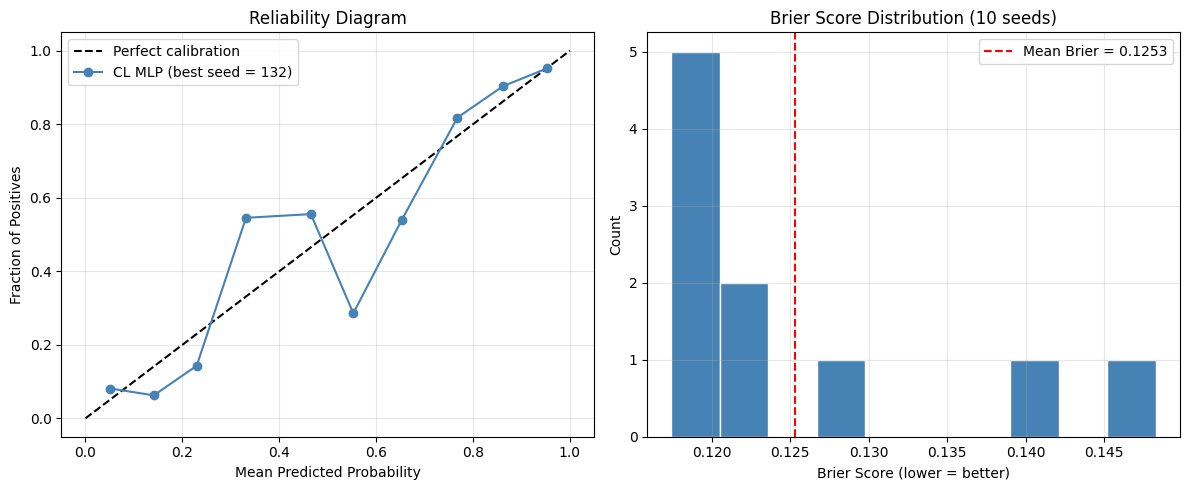

Mean Brier Score: 0.1253 +/- 0.0106


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

best_out = out_by_seed[best_seed]
y_true   = best_out["y_test"]
y_prob   = best_out["y_prob"]
frac_pos, mean_pred = calibration_curve(y_true, y_prob, n_bins=10, strategy="uniform")

axes[0].plot([0, 1], [0, 1], "k--", label="Perfect calibration")
axes[0].plot(mean_pred, frac_pos, "o-", color="steelblue",
             label=f"CL MLP (best seed = {best_seed})")
axes[0].set_xlabel("Mean Predicted Probability")
axes[0].set_ylabel("Fraction of Positives")
axes[0].set_title("Reliability Diagram")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].hist(global_df["brier"].values, bins=10, color="steelblue", edgecolor="white")
axes[1].axvline(global_df["brier"].mean(), color="red", linestyle="--",
                 label=f"Mean Brier = {global_df['brier'].mean():.4f}")
axes[1].set_xlabel("Brier Score (lower = better)")
axes[1].set_ylabel("Count")
axes[1].set_title("Brier Score Distribution (10 seeds)")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("cl_calibration.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Mean Brier Score: {global_df['brier'].mean():.4f} "
      f"+/- {global_df['brier'].std(ddof=1):.4f}")


## 12. Baseline Model Comparison (LR + RF + XGBoost vs MLP)

Logistic Regression and Random Forest provide linear and bagged-tree baselines. We also
include **XGBoost** as the key gradient-boosted tree baseline expected for tabular
medical data. XGBoost is treated as a required experiment dependency so the tabular
baseline is always part of the centralized comparison.

All baselines reuse the same Setting D train/validation/test splits, preprocessing, and
validation-threshold tuning, then are compared to the MLP with paired Wilcoxon tests and
Holm-Bonferroni correction. Those paired tests are seed-level and descriptive; the
paper's baseline comparison is the paired bootstrap, under which the centralized MLP and
pooled logistic regression are indistinguishable.

In [22]:
def run_baseline(df_raw, model_name, seed):
    set_seed(seed)
    df_tv, df_test = create_fixed_external_test_split(df_raw, seed=TEST_SEED)
    df_tr, df_val  = create_inner_train_val_split(df_tv, seed=seed)

    X_tr, X_va, X_te, y_tr, y_va, y_te, _ = FINAL_PREPROCESSOR(
        df_tr, df_val, df_test)
    y_tr_i = y_tr.astype(int)

    if model_name == "LogisticRegression":
        clf = LogisticRegression(max_iter=2000, class_weight="balanced",
                                  C=1.0, random_state=seed)
    elif model_name == "RandomForest":
        clf = RandomForestClassifier(n_estimators=200, max_depth=8,
                                      class_weight="balanced", random_state=seed,
                                      n_jobs=-1)
    elif model_name == "XGBoost":
        n_pos = max(int((y_tr_i == 1).sum()), 1)
        n_neg = max(int((y_tr_i == 0).sum()), 1)
        clf = XGBClassifier(
            n_estimators=300, max_depth=3, learning_rate=0.03,
            subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0,
            objective="binary:logistic", eval_metric="logloss",
            scale_pos_weight=n_neg / n_pos, random_state=seed,
            n_jobs=-1, tree_method="hist")
    else:
        raise ValueError(model_name)

    clf.fit(X_tr, y_tr_i)
    y_va_p = clf.predict_proba(X_va)[:, 1]
    best_thr, _ = find_best_threshold(y_va.astype(int), y_va_p)
    y_te_p = clf.predict_proba(X_te)[:, 1]
    m = compute_metrics(y_te.astype(int), y_te_p, threshold=best_thr)
    m["model"] = model_name; m["seed"] = seed
    return m


baseline_models = ["LogisticRegression", "RandomForest", "XGBoost"]

print(f"Running baseline models ({', '.join(baseline_models)})...", flush=True)
baseline_rows = []
for model_name in baseline_models:
    print(f"  {model_name}", end="", flush=True)
    for seed in SEEDS:
        print(".", end="", flush=True)
        baseline_rows.append(run_baseline(df, model_name, seed))
    print()
baseline_df = pd.DataFrame(baseline_rows)
print("Done.")


Running baseline models (LogisticRegression, RandomForest, XGBoost)...
  LogisticRegression..........
  RandomForest..........
  XGBoost..........
Done.


In [23]:
# Comparison table (mean +/- std, 10 seeds)
comp_models = {"MLP (CL)": global_df}
for model_name in baseline_models:
    comp_models[model_name] = baseline_df[baseline_df["model"] == model_name]

print("Model Comparison (mean +/- std, n=10 seeds):")
print(f"{'Model':22s}  {'AUROC':>14s}  {'AUPRC':>14s}  {'F1':>14s}  {'Recall':>14s}")
print("-" * 86)
for name, sub_df in comp_models.items():
    cells = []
    for m in ["auroc", "auprc", "f1", "recall"]:
        mu = sub_df[m].mean()
        sd = sub_df[m].std(ddof=1)
        cells.append(f"{mu:.4f}+/-{sd:.4f}")
    print(f"{name:22s}  {cells[0]:>14s}  {cells[1]:>14s}  "
          f"{cells[2]:>14s}  {cells[3]:>14s}")


# Paired Wilcoxon vs MLP, Holm-Bonferroni across metrics
print("\nPaired Wilcoxon (MLP vs each baseline), Holm-Bonferroni corrected:")
metrics_for_test = ["auroc", "auprc", "f1", "recall"]
baseline_stat_rows = []
for opp in baseline_models:
    pvals = []
    raw = []
    for m in metrics_for_test:
        v_mlp = global_df.sort_values("seed")[m].values
        v_opp = (baseline_df[baseline_df["model"] == opp]
.sort_values("seed")[m].values)
        try:
            stat, p = wilcoxon(v_mlp, v_opp)
        except Exception:
            stat, p = np.nan, 1.0
        d = cohens_d_paired(v_mlp, v_opp)
        raw.append((m, v_mlp.mean() - v_opp.mean(), stat, p, d))
        pvals.append(p)
    p_adj = holm_bonferroni(pvals)
    print(f"\n  MLP vs {opp}")
    for (m, diff, stat, p, d), pa in zip(raw, p_adj):
        sig = "*" if pa < ALPHA else " "
        print(f"    {m:8s} mu_diff={diff:+.4f}  p={p:.4f}  "
              f"p_Holm={pa:.4f}{sig}  d={d:+.3f}")
        baseline_stat_rows.append({"opponent": opp, "metric": m,
                                    "mean_diff": diff, "p_raw": p,
                                    "p_holm": pa, "cohen_d": d,
                                    "significant": pa < ALPHA})

baseline_stat_df = pd.DataFrame(baseline_stat_rows)

# Machine-readable baseline exports
model_summary_rows = []
for name, sub_df in comp_models.items():
    for m in ["auroc", "auprc", "f1", "recall", "precision", "accuracy", "brier"]:
        if m not in sub_df.columns:
            continue
        vals = sub_df[m].dropna().values
        mu, lo, hi = ci_95(vals)
        model_summary_rows.append({
            "model": name, "metric": m, "mean": mu, "ci_lo": lo, "ci_hi": hi,
            "std": float(np.std(vals, ddof=1)) if len(vals) > 1 else np.nan,
            "n_seeds": int(len(vals)),
        })
cl_model_comparison_df = pd.DataFrame(model_summary_rows)
baseline_df.to_csv("cl_baseline_by_seed.csv", index=False)
baseline_stat_df.to_csv("cl_baseline_stats.csv", index=False)
cl_model_comparison_df.to_csv("cl_model_comparison_summary.csv", index=False)
print("\nSaved baseline exports -> cl_baseline_by_seed.csv, "
      "cl_baseline_stats.csv, cl_model_comparison_summary.csv")


Model Comparison (mean +/- std, n=10 seeds):
Model                            AUROC           AUPRC              F1          Recall
--------------------------------------------------------------------------------------
MLP (CL)                0.8989+/-0.0073  0.9076+/-0.0064  0.8512+/-0.0065  0.9245+/-0.0300
LogisticRegression      0.9054+/-0.0023  0.9090+/-0.0022  0.8569+/-0.0071  0.9225+/-0.0341
RandomForest            0.8933+/-0.0050  0.8868+/-0.0099  0.8582+/-0.0182  0.9265+/-0.0398
XGBoost                 0.9067+/-0.0044  0.9113+/-0.0060  0.8504+/-0.0146  0.9186+/-0.0390

Paired Wilcoxon (MLP vs each baseline), Holm-Bonferroni corrected:

  MLP vs LogisticRegression
    auroc    mu_diff=-0.0064  p=0.0137  p_Holm=0.0547   d=-0.907
    auprc    mu_diff=-0.0014  p=0.4922  p_Holm=0.9844   d=-0.216
    f1       mu_diff=-0.0058  p=0.0273  p_Holm=0.0820   d=-0.846
    recall   mu_diff=+0.0020  p=0.7070  p_Holm=0.9844   d=+0.051

  MLP vs RandomForest
    auroc    mu_diff=+0.0057  p=0.013

In [24]:
def run_baseline_with_hospitals(df_raw, model_name, seed, test_seed=TEST_SEED):
    """Same fit as run_baseline(), plus per-hospital evaluation and raw preds."""
    set_seed(seed)
    df_tv, df_test = create_fixed_external_test_split(df_raw, seed=test_seed)
    df_tr, df_val = create_inner_train_val_split(df_tv, seed=seed)
    X_tr, X_va, X_te, y_tr, y_va, y_te, _ = FINAL_PREPROCESSOR(
        df_tr, df_val, df_test)
    y_tr_i = y_tr.astype(int)
 
    if model_name == "LogisticRegression":
        clf = LogisticRegression(max_iter=2000, class_weight="balanced",
                                 C=1.0, random_state=seed)
    elif model_name == "RandomForest":
        clf = RandomForestClassifier(n_estimators=200, max_depth=8,
                                     class_weight="balanced",
                                     random_state=seed, n_jobs=-1)
    elif model_name == "XGBoost":
        n_pos = max(int((y_tr_i == 1).sum()), 1)
        n_neg = max(int((y_tr_i == 0).sum()), 1)
        clf = XGBClassifier(
            n_estimators=300, max_depth=3, learning_rate=0.03,
            subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0,
            objective="binary:logistic", eval_metric="logloss",
            scale_pos_weight=n_neg / n_pos, random_state=seed,
            n_jobs=-1, tree_method="hist")
    else:
        raise ValueError(model_name)
 
    clf.fit(X_tr, y_tr_i)
    y_va_p = clf.predict_proba(X_va)[:, 1]
    best_thr, _ = find_best_threshold(y_va.astype(int), y_va_p)
    y_te_p = clf.predict_proba(X_te)[:, 1]
 
    m = compute_metrics(y_te.astype(int), y_te_p, threshold=best_thr)
    m.update({"model": model_name, "seed": seed, "threshold": float(best_thr)})
 
    hospital_rows, hospital_preds = [], {}
    for hosp in df_test[HOSPITAL_COL].unique():
        mask = (df_test[HOSPITAL_COL].values == hosp)
        y_h = y_te[mask].astype(int)
        if len(y_h) < 5:
            continue
        p_h = clf.predict_proba(X_te[mask])[:, 1]
        hm = compute_metrics(y_h, p_h, threshold=best_thr)
        hm.update({"hospital": hosp, "n_test": int(len(y_h)),
                   "model": model_name, "seed": seed})
        hospital_rows.append(hm)
        hospital_preds[hosp] = (y_h, p_h, float(best_thr))
 
    return {"global": m, "per_hospital": hospital_rows,
            "hospital_preds": hospital_preds,
            "pooled_threshold": float(best_thr)}
 
 
print("Centralized Logistic Regression (pooled data, per-hospital + bootstrap)")
print("=" * 78, flush=True)
 
cl_lr_global_rows, cl_lr_hosp_rows = [], []
for seed in SEEDS:
    print(".", end="", flush=True)
    out = run_baseline_with_hospitals(df, "LogisticRegression", seed)
    register_predictions("centralized", "CL_LR", seed,
                         out["hospital_preds"], out["pooled_threshold"])
    cl_lr_global_rows.append(out["global"])
    cl_lr_hosp_rows.extend(out["per_hospital"])
print()
 
cl_lr_global_df = pd.DataFrame(cl_lr_global_rows)
cl_lr_hosp_df = pd.DataFrame(cl_lr_hosp_rows)
 
# Macro / worst scalars per seed, matching the CL MLP convention
cl_lr_macro_rows = []
for seed, sub_ in cl_lr_hosp_df.groupby("seed"):
    cl_lr_macro_rows.append({
        "seed": seed,
        "macro_auprc": float(sub_["auprc"].mean()),
        "worst_auprc": float(sub_["auprc"].min()),
        "macro_normalized_auprc": float(sub_["normalized_auprc"].mean()),
        "worst_normalized_auprc": float(sub_["normalized_auprc"].min()),
        "macro_brier": float(sub_["brier"].mean())})
cl_lr_macro_df = pd.DataFrame(cl_lr_macro_rows)
 
print("\nSeed-level summary (mean [95% t-CI], 10 seeds)")
print("-" * 78)
for m in ["macro_auprc", "worst_auprc", "macro_normalized_auprc",
          "worst_normalized_auprc", "macro_brier"]:
    mu, lo, hi = ci_95(cl_lr_macro_df[m].dropna().values)
    print(f"  {m:24s}: {mu:.4f} [{lo:.4f}, {hi:.4f}]")
mu, lo, hi = ci_95(cl_lr_global_df["brier"].dropna().values)
print(f"  {'global_brier':24s}: {mu:.4f} [{lo:.4f}, {hi:.4f}]")
 
# ---- Patient-level bootstrap, same protocol as every other model -----------
boot_cl_lr = bootstrap_ci_table("centralized", "CL_LR")
boot_cl_lr.to_csv("cl_lr_bootstrap_ci.csv", index=False)
 
print("\nPatient-level bootstrap (paper table values)")
print("-" * 78)
for scope, metric, label in [("macro", "auprc", "Macro AUPRC"),
                             ("worst", "auprc", "Worst AUPRC"),
                             ("macro", "normalized_auprc", "Macro nAUPRC"),
                             ("worst", "normalized_auprc", "Worst nAUPRC"),
                             ("pooled", "brier", "Global Brier")]:
    r = boot_cl_lr[(boot_cl_lr["scope"] == scope) &
                   (boot_cl_lr["metric"] == metric)]
    if r.empty:
        continue
    r = r.iloc[0]
    print(f"  {label:16s}: {r['mean']:.3f} [{r['ci_lo']:.3f}, {r['ci_hi']:.3f}]"
          f"   (valid {r['valid_frac']:.2f})")
 
# ---- Paired bootstrap: CL-LR against CL-MLP, same resampled patients -------
print("\nPaired bootstrap, CL-LR minus CL-MLP (identical resampled patients)")
print("-" * 78)
cl_lr_pairs = []
for scope in ["macro", "worst"]:
    r = bootstrap_paired_difference("centralized", "CL_LR",
                                    "centralized", "CL_MLP",
                                    metric="auprc", scope=scope)
    cl_lr_pairs.append(r)
    verdict = "DISTINGUISHABLE" if r["excludes_zero"] else "not distinguishable"
    print(f"  {scope:6s} AUPRC  diff={r['mean_diff']:+.4f}  "
          f"95% CI [{r['ci_lo']:+.4f}, {r['ci_hi']:+.4f}]  "
          f"p={r['p_two_sided_boot']:.3f}  {verdict}")
 
pd.DataFrame(cl_lr_pairs).to_csv("cl_lr_vs_mlp_paired.csv", index=False)
cl_lr_global_df.to_csv("cl_lr_global_by_seed.csv", index=False)
cl_lr_hosp_df.to_csv("cl_lr_per_hospital.csv", index=False)
cl_lr_macro_df.to_csv("cl_lr_macro_by_seed.csv", index=False)
print("\nSaved: cl_lr_bootstrap_ci.csv, cl_lr_vs_mlp_paired.csv, "
      "cl_lr_global_by_seed.csv, cl_lr_per_hospital.csv, cl_lr_macro_by_seed.csv")

Centralized Logistic Regression (pooled data, per-hospital + bootstrap)
..........

Seed-level summary (mean [95% t-CI], 10 seeds)
------------------------------------------------------------------------------
  macro_auprc             : 0.8972 [0.8951, 0.8993]
  worst_auprc             : 0.8133 [0.8080, 0.8187]
  macro_normalized_auprc  : 0.6172 [0.6040, 0.6304]
  worst_normalized_auprc  : 0.3395 [0.2980, 0.3810]
  macro_brier             : 0.1208 [0.1190, 0.1225]
  global_brier            : 0.1182 [0.1168, 0.1195]

Patient-level bootstrap (paper table values)
------------------------------------------------------------------------------
  Macro AUPRC     : 0.897 [0.835, 0.952]   (valid 1.00)
  Worst AUPRC     : 0.801 [0.651, 0.906]   (valid 1.00)
  Macro nAUPRC    : 0.647 [0.377, 0.886]   (valid 1.00)
  Worst nAUPRC    : 0.247 [-0.562, 0.775]   (valid 1.00)
  Global Brier    : 0.118 [0.088, 0.152]   (valid 1.00)

Paired bootstrap, CL-LR minus CL-MLP (identical resampled patients)
---

## 12.1 Small-Data Sensitivity - Train-Only Augmentation (Gaussian/SMOTE) and Top-5 Features

The UCI Heart dataset has fewer than one thousand rows. This section asks whether the
CL/FL conclusions depend on using all Setting D features or on the absence of
augmentation.

Two variants are evaluated without touching validation/test data:

1. **Gaussian train-only augmentation:** duplicate the training matrix once and add
   small Gaussian jitter only to standardized numerical columns. Categorical one-hot
   columns and missingness indicators are left unchanged.
2. **Top-5 feature selection:** choose the top five transformed Setting D columns using
   an L1-regularized logistic regression fitted on the training split only, then train
   the same MLP on that reduced feature matrix.

This is a sensitivity diagnostic and is not reported in the paper.

In [25]:
RUN_CL_SMALL_DATA_SENSITIVITY = True
CL_SENSITIVITY_VARIANTS = ["gaussian_aug", "smote_aug", "top5_lr"]
TOP_K_FEATURES = 5
AUG_COPIES = 1
AUG_NOISE_STD = 0.05
SMOTE_TARGET_RATIO = 1.0
SMOTE_K_NEIGHBORS = 5


def select_top_k_lr_features(X_train, y_train, feature_cols, k=5, seed=42):
    """Train-only embedded feature selection on transformed Setting-D columns."""
    k = min(int(k), X_train.shape[1])
    clf = LogisticRegression(
        penalty="l1", solver="liblinear", class_weight="balanced",
        C=0.25, max_iter=2000, random_state=seed)
    selector_model = "logreg_l1"
    try:
        clf.fit(X_train, y_train.astype(int))
        coefficients = clf.coef_.ravel().astype(float)
        scores = np.abs(coefficients)
    except Exception:
        coefficients = np.zeros(X_train.shape[1], dtype=float)
        scores = np.zeros(X_train.shape[1], dtype=float)

    if not np.isfinite(scores).any() or np.nanmax(scores) <= 0:
        # Conservative fallback if L1 zeros everything on a small split.
        clf = LogisticRegression(
            penalty="l2", solver="liblinear", class_weight="balanced",
            C=1.0, max_iter=2000, random_state=seed)
        clf.fit(X_train, y_train.astype(int))
        coefficients = clf.coef_.ravel().astype(float)
        scores = np.abs(coefficients)
        selector_model = "logreg_l2_fallback"

    order = np.argsort(scores)[::-1][:k]
    selected = [feature_cols[i] for i in order]
    return order.astype(int), selected, scores, coefficients


def augment_train_matrix(X_train, y_train, feature_cols, seed=42,
                         copies=1, noise_std=0.05,
                         continuous_names=NUMERICAL_COLS):
    """Duplicate train rows and jitter only standardized numerical columns."""
    X_train = np.asarray(X_train, dtype=np.float32)
    y_train = np.asarray(y_train, dtype=np.float32).ravel()
    copies = int(copies)
    if copies <= 0 or len(X_train) == 0:
        return X_train, y_train

    rng = np.random.default_rng(seed)
    continuous_idx = [
        i for i, name in enumerate(feature_cols)
        if name in set(continuous_names)
    ]
    X_parts = [X_train]
    y_parts = [y_train]
    for _ in range(copies):
        X_new = X_train.copy()
        if continuous_idx:
            X_new[:, continuous_idx] += rng.normal(
                0.0, noise_std, size=(X_new.shape[0], len(continuous_idx))
            ).astype(np.float32)
        X_parts.append(X_new)
        y_parts.append(y_train.copy())
    return np.vstack(X_parts).astype(np.float32), np.concatenate(y_parts).astype(np.float32)


def smote_train_matrix(X_train, y_train, feature_cols, seed=42,
                       target_ratio=1.0, k_neighbors=5,
                       continuous_names=NUMERICAL_COLS):
    """SMOTE-style train-only oversampling that preserves binary indicator columns.

    This NumPy implementation avoids sklearn.neighbors/joblib subprocess calls on
    Windows. Numeric columns are interpolated between minority-class neighbors.
    One-hot categorical columns and missingness indicators are copied from one of
    the two neighbors, avoiding invalid fractional values such as 0.37.
    """
    X_train = np.asarray(X_train, dtype=np.float32)
    y_train = np.asarray(y_train).astype(int).ravel()
    if len(X_train) == 0 or len(np.unique(y_train)) < 2:
        return X_train, y_train.astype(np.float32)

    classes, counts = np.unique(y_train, return_counts=True)
    minority_class = classes[np.argmin(counts)]
    majority_count = int(np.max(counts))
    minority_count = int(np.min(counts))
    desired_minority = int(np.ceil(float(target_ratio) * majority_count))
    n_generate = max(0, desired_minority - minority_count)
    if n_generate <= 0:
        return X_train, y_train.astype(np.float32)

    X_min = X_train[y_train == minority_class]
    if len(X_min) < 2:
        return X_train, y_train.astype(np.float32)

    rng = np.random.default_rng(seed)
    continuous_idx = np.array([
        i for i, name in enumerate(feature_cols)
        if name in set(continuous_names)
    ], dtype=int)
    categorical_idx = np.array([
        i for i in range(X_train.shape[1])
        if i not in set(continuous_idx.tolist())
    ], dtype=int)

    # Dataset is small, so a dense NumPy distance matrix is simpler and avoids
    # joblib/loky subprocess calls that can fail on Windows Store Python.
    if len(continuous_idx):
        X_nn = X_min[:, continuous_idx].astype(np.float32)
    else:
        X_nn = X_min.astype(np.float32)
    diff = X_nn[:, None, :] - X_nn[None, :, :]
    dist = np.sum(diff * diff, axis=2)
    np.fill_diagonal(dist, np.inf)
    k_eff = max(1, min(int(k_neighbors), len(X_min) - 1))
    neigh_ind = np.argsort(dist, axis=1)[:, :k_eff]

    synthetic = []
    for _ in range(n_generate):
        i = int(rng.integers(0, len(X_min)))
        j = int(rng.choice(neigh_ind[i]))
        xi = X_min[i]
        xj = X_min[j]
        gap = float(rng.random())
        x_new = xi.copy()
        if len(continuous_idx):
            x_new[continuous_idx] = xi[continuous_idx] + gap * (
                xj[continuous_idx] - xi[continuous_idx])
        if len(categorical_idx):
            take_j = rng.random(len(categorical_idx)) < 0.5
            x_new[categorical_idx] = np.where(
                take_j, xj[categorical_idx], xi[categorical_idx])
        synthetic.append(x_new)

    X_syn = np.vstack(synthetic).astype(np.float32)
    y_syn = np.full(len(X_syn), minority_class, dtype=np.float32)
    return (np.vstack([X_train, X_syn]).astype(np.float32),
            np.concatenate([y_train.astype(np.float32), y_syn]).astype(np.float32))


def run_cl_small_data_variant(df_raw, seed, variant,
                              top_k=TOP_K_FEATURES,
                              aug_copies=AUG_COPIES,
                              aug_noise_std=AUG_NOISE_STD,
                              smote_target_ratio=SMOTE_TARGET_RATIO,
                              smote_k_neighbors=SMOTE_K_NEIGHBORS):
    set_seed(seed)
    df_tv, df_test = create_fixed_external_test_split(df_raw, seed=TEST_SEED)
    df_tr, df_val = create_inner_train_val_split(df_tv, seed=seed)

    X_tr, X_va, X_te, y_tr, y_va, y_te, info = FINAL_PREPROCESSOR(
        df_tr, df_val, df_test)
    feature_cols = list(info["feature_columns"])
    original_n_features = len(feature_cols)
    selected_features = feature_cols
    selected_scores = None
    selected_coefficients = None

    if variant == "top5_lr":
        idx, selected_features, selected_scores, selected_coefficients = select_top_k_lr_features(
            X_tr, y_tr, feature_cols, k=top_k, seed=seed)
        X_tr, X_va, X_te = X_tr[:, idx], X_va[:, idx], X_te[:, idx]
    elif variant == "gaussian_aug":
        X_tr, y_tr = augment_train_matrix(
            X_tr, y_tr, feature_cols, seed=seed,
            copies=aug_copies, noise_std=aug_noise_std)
    elif variant == "smote_aug":
        X_tr, y_tr = smote_train_matrix(
            X_tr, y_tr, feature_cols, seed=seed,
            target_ratio=smote_target_ratio,
            k_neighbors=smote_k_neighbors)
    else:
        raise ValueError(f"Unknown CL sensitivity variant: {variant}")

    t_start = time.perf_counter()
    model, history, _ = train_centralized_mlp(
        X_tr, y_tr, X_va, y_va, epochs=EPOCHS, patience=PATIENCE)
    train_time_s = time.perf_counter() - t_start

    y_va_t, y_va_p = evaluate_loader(model, make_loader(X_va, y_va), DEVICE)
    best_thr, _ = find_best_threshold(y_va_t, y_va_p)

    y_te_t, y_te_p = evaluate_loader(model, make_loader(X_te, y_te), DEVICE)
    m = compute_metrics(y_te_t, y_te_p, threshold=best_thr)
    m.update({
        "analysis": "small_data_sensitivity",
        "system": "centralized_mlp",
        "variant": variant,
        "seed": seed,
        "threshold": best_thr,
        "train_time_s": train_time_s,
        "n_features": X_tr.shape[1],
        "original_n_features": original_n_features,
        "n_train_original": len(df_tr),
        "n_train_effective": len(y_tr),
        "aug_copies": aug_copies if variant == "gaussian_aug" else 0,
        "aug_noise_std": aug_noise_std if variant == "gaussian_aug" else 0.0,
        "augmentation_method": variant if variant in {"gaussian_aug", "smote_aug"} else "none",
        "smote_target_ratio": smote_target_ratio if variant == "smote_aug" else 0.0,
        "smote_k_neighbors": smote_k_neighbors if variant == "smote_aug" else 0,
        "selected_features": "|".join(selected_features),
    })

    hospital_rows = []
    for hosp in df_test[HOSPITAL_COL].unique():
        mask = (df_test[HOSPITAL_COL].values == hosp)
        if mask.sum() < 5:
            continue
        y_h_t, y_h_p = evaluate_loader(
            model, make_loader(X_te[mask], y_te[mask]), DEVICE)
        hm = compute_metrics(y_h_t, y_h_p, threshold=best_thr)
        hm.update({
            "analysis": "small_data_sensitivity",
            "system": "centralized_mlp",
            "variant": variant,
            "hospital": hosp,
            "n_test": int(mask.sum()),
            "seed": seed,
            "n_features": X_tr.shape[1],
        })
        hospital_rows.append(hm)

    feature_rows = []
    if variant == "top5_lr" and selected_scores is not None:
        for rank, feat in enumerate(selected_features, 1):
            full_idx = feature_cols.index(feat)
            feature_rows.append({
                "system": "centralized_mlp",
                "variant": variant,
                "seed": seed,
                "rank": rank,
                "feature": feat,
                "selector_score": float(selected_scores[full_idx]),
                "coefficient": float(selected_coefficients[full_idx]),
                "abs_coefficient": float(abs(selected_coefficients[full_idx])),
                "direction": ("positive" if selected_coefficients[full_idx] > 0
                              else "negative" if selected_coefficients[full_idx] < 0
                              else "zero"),
            })

    return {"global": m, "per_hospital": hospital_rows,
            "selected_features": feature_rows}


if RUN_CL_SMALL_DATA_SENSITIVITY:
    cl_sens_global_rows = []
    cl_sens_hospital_rows = []
    cl_top5_feature_rows = []

    # Reuse the already computed Setting-D final result as the non-augmented full-feature baseline.
    if "global_df" in globals():
        base = global_df.copy()
        base["analysis"] = "small_data_sensitivity"
        base["system"] = "centralized_mlp"
        base["variant"] = "setting_d_full"
        base["original_n_features"] = base.get("n_features", 24)
        base["n_train_original"] = np.nan
        base["n_train_effective"] = np.nan
        base["aug_copies"] = 0
        base["aug_noise_std"] = 0.0
        base["augmentation_method"] = "none"
        base["smote_target_ratio"] = 0.0
        base["smote_k_neighbors"] = 0
        base["selected_features"] = "ALL"
        cl_sens_global_rows.extend(base.to_dict("records"))
    if "per_hosp_df" in globals():
        ph_base = per_hosp_df.copy()
        ph_base["analysis"] = "small_data_sensitivity"
        ph_base["system"] = "centralized_mlp"
        ph_base["variant"] = "setting_d_full"
        cl_sens_hospital_rows.extend(ph_base.to_dict("records"))

    print("Running CL small-data sensitivity: Gaussian/SMOTE augmentation and top-5 features...")
    for variant in CL_SENSITIVITY_VARIANTS:
        print(f"  {variant}", end="", flush=True)
        for seed in SEEDS:
            print(".", end="", flush=True)
            out = run_cl_small_data_variant(df, seed, variant)
            cl_sens_global_rows.append(out["global"])
            cl_sens_hospital_rows.extend(out["per_hospital"])
            cl_top5_feature_rows.extend(out["selected_features"])
        print()

    cl_small_data_global_df = pd.DataFrame(cl_sens_global_rows)
    cl_small_data_per_hospital_df = pd.DataFrame(cl_sens_hospital_rows)
    cl_top5_selected_features_df = pd.DataFrame(cl_top5_feature_rows)

    summary_rows = []
    for variant, sub in cl_small_data_global_df.groupby("variant"):
        for metric in ["auroc", "auprc", "normalized_auprc", "f1", "brier"]:
            mu, lo, hi = ci_95(sub[metric].dropna().values)
            summary_rows.append({
                "analysis": "small_data_sensitivity",
                "system": "centralized_mlp",
                "variant": variant,
                "metric": metric,
                "mean": mu,
                "ci_lo": lo,
                "ci_hi": hi,
                "n_seeds": int(sub["seed"].nunique()) if "seed" in sub else len(sub),
            })
    cl_small_data_sensitivity_summary_df = pd.DataFrame(summary_rows)

    cl_small_data_global_df.to_csv("cl_small_data_sensitivity_global.csv", index=False)
    cl_small_data_per_hospital_df.to_csv("cl_small_data_sensitivity_per_hospital.csv", index=False)
    cl_top5_selected_features_df.to_csv("cl_top5_selected_features.csv", index=False)
    cl_small_data_sensitivity_summary_df.to_csv("cl_small_data_sensitivity_summary.csv", index=False)

    print("CL small-data sensitivity summary:")
    print(cl_small_data_sensitivity_summary_df.to_string(index=False, float_format="%.4f"))
    if len(cl_top5_selected_features_df):
        freq = (cl_top5_selected_features_df.groupby("feature")["seed"]
                .nunique().sort_values(ascending=False).reset_index(name="n_seeds_selected"))
        print("\nTop-5 selected feature frequency:")
        print(freq.to_string(index=False))
    print("Saved: cl_small_data_sensitivity_*.csv and cl_top5_selected_features.csv")
else:
    print("CL small-data sensitivity skipped.")


Running CL small-data sensitivity: Gaussian/SMOTE augmentation and top-5 features...
  gaussian_aug..........
  smote_aug..........
  top5_lr..........
CL small-data sensitivity summary:
              analysis          system        variant           metric   mean  ci_lo  ci_hi  n_seeds
small_data_sensitivity centralized_mlp   gaussian_aug            auroc 0.8984 0.8927 0.9040       10
small_data_sensitivity centralized_mlp   gaussian_aug            auprc 0.9075 0.9010 0.9140       10
small_data_sensitivity centralized_mlp   gaussian_aug normalized_auprc 0.7924 0.7779 0.8069       10
small_data_sensitivity centralized_mlp   gaussian_aug               f1 0.8516 0.8471 0.8561       10
small_data_sensitivity centralized_mlp   gaussian_aug            brier 0.1262 0.1197 0.1326       10
small_data_sensitivity centralized_mlp setting_d_full            auroc 0.8989 0.8937 0.9041       10
small_data_sensitivity centralized_mlp setting_d_full            auprc 0.9076 0.9031 0.9122       10
small

## 13. Interpretability - SHAP

We use SHAP to answer two questions:

> **Q1.** What features drive the centralized model's predictions overall?
> **Q2.** Are those features stable across hospitals, or does each site rely on a
> different signal?

Q1 is the standard global-importance use of SHAP. For Q2 we recompute the SHAP
importance separately *within each hospital's slice of the test set* and report the
**Spearman rank correlation** between hospital-specific importance rankings. Low
correlation means the same global model assigns different reasons to its predictions at
different hospitals.

Divergent per-hospital attributions would be a mechanistic reason to try
personalisation, but on this corpus post-hoc personalized FL produces no resolvable
improvement under the paired bootstrap (macro Brier p = 0.622). This section is a
diagnostic and is not reported in the paper.

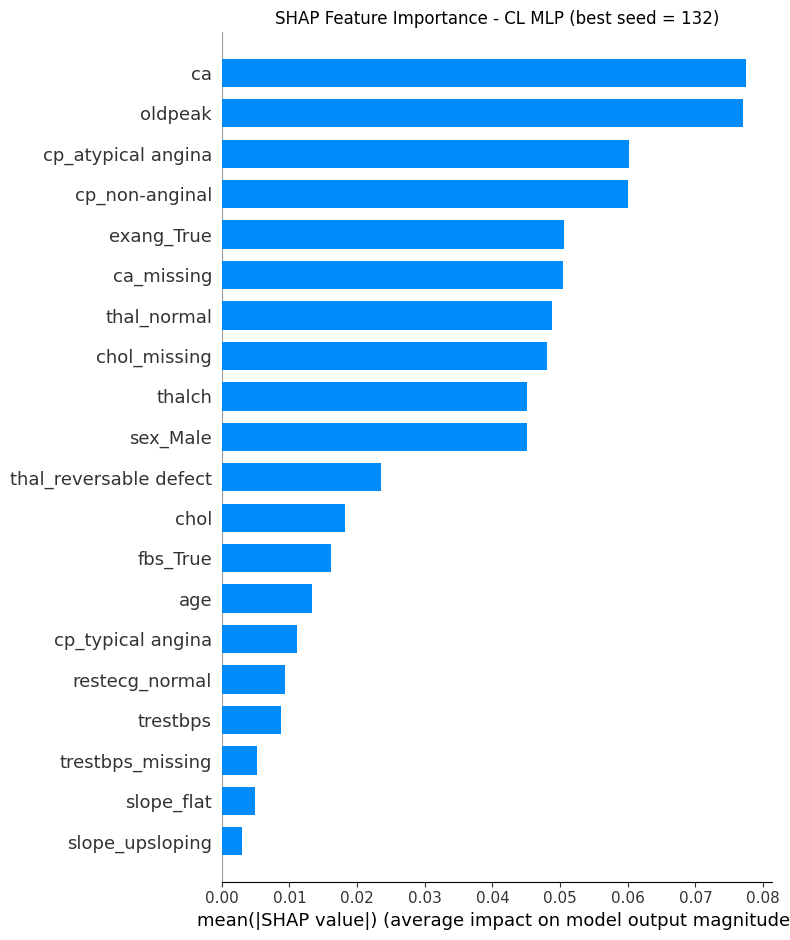

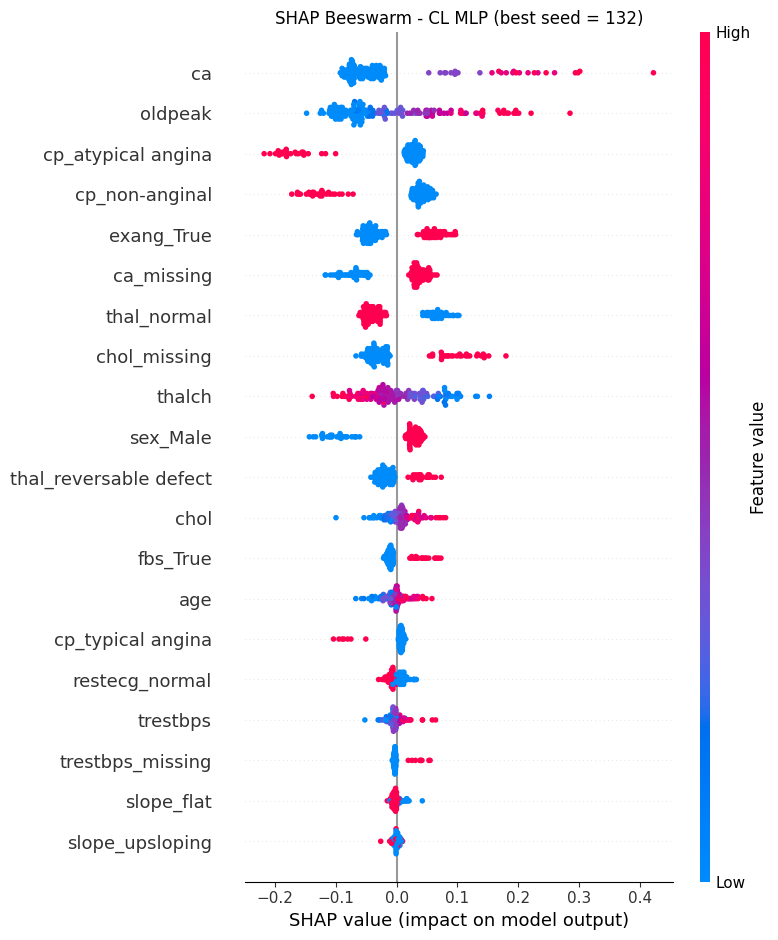

Q1 - Top 15 globally important features (CL):
               feature  mean_abs_shap
                    ca       0.077428
               oldpeak       0.077085
    cp_atypical angina       0.060195
        cp_non-anginal       0.060045
            exang_True       0.050578
            ca_missing       0.050498
           thal_normal       0.048873
          chol_missing       0.047990
                thalch       0.045072
              sex_Male       0.045061
thal_reversable defect       0.023477
                  chol       0.018214
              fbs_True       0.016119
                   age       0.013353
     cp_typical angina       0.011187

Train-only Logistic Regression coefficient ranking (CL, top 10):
 lr_rank            feature  coefficient  abs_coefficient direction
       1 cp_atypical angina      -1.4377           1.4377  negative
       2     cp_non-anginal      -1.0459           1.0459  negative
       3        thal_normal      -1.0068           1.0068  negative
       4

In [26]:
def lr_feature_coefficient_table(X_train, y_train, feature_cols, seed=42):
    """Fit train-only LR-L1 and return signed coefficient ranking."""
    clf = LogisticRegression(
        penalty="l1", solver="liblinear", class_weight="balanced",
        C=0.25, max_iter=2000, random_state=seed)
    selector_model = "logreg_l1"
    y_train = np.asarray(y_train).astype(int).ravel()
    try:
        clf.fit(X_train, y_train)
        coef = clf.coef_.ravel().astype(float)
    except Exception:
        coef = np.zeros(len(feature_cols), dtype=float)

    if not np.isfinite(coef).any() or np.nanmax(np.abs(coef)) <= 0:
        clf = LogisticRegression(
            penalty="l2", solver="liblinear", class_weight="balanced",
            C=1.0, max_iter=2000, random_state=seed)
        clf.fit(X_train, y_train)
        coef = clf.coef_.ravel().astype(float)
        selector_model = "logreg_l2_fallback"

    lr_df = pd.DataFrame({
        "feature": feature_cols,
        "coefficient": coef,
        "abs_coefficient": np.abs(coef),
        "direction": np.where(coef > 0, "positive",
                              np.where(coef < 0, "negative", "zero")),
        "selector_model": selector_model,
    }).sort_values("abs_coefficient", ascending=False).reset_index(drop=True)
    lr_df["lr_rank"] = np.arange(1, len(lr_df) + 1)
    return lr_df


best_model_obj = out_by_seed[best_seed]["model"].eval()
X_test_np      = out_by_seed[best_seed]["X_test"]
feat_cols      = out_by_seed[best_seed]["feature_cols"]
df_test_best   = out_by_seed[best_seed]["df_test"]

X_bg  = pd.DataFrame(X_test_np[:50],  columns=feat_cols)
X_exp = pd.DataFrame(X_test_np[:150], columns=feat_cols)


def predict_proba_fn(X_arr):
    if isinstance(X_arr, pd.DataFrame):
        X_arr = X_arr.values
    X_arr = np.asarray(X_arr, dtype=np.float32)
    if X_arr.ndim == 1:
        X_arr = X_arr.reshape(1, -1)
    with torch.no_grad():
        t = torch.from_numpy(X_arr).to(DEVICE)
        logits = best_model_obj(t).view(-1).cpu().numpy()
    return sigmoid_np(logits)


explainer   = shap.Explainer(predict_proba_fn, X_bg, feature_names=feat_cols)
shap_values = explainer(X_exp)
sv = shap_values.values
if sv.ndim == 3:
    sv = sv[:,:, 0]

# Q1. Global SHAP importance
shap.summary_plot(sv, X_exp, plot_type="bar", show=False)
plt.title(f"SHAP Feature Importance - CL MLP (best seed = {best_seed})")
plt.tight_layout(); plt.savefig("cl_shap_bar.png", dpi=150, bbox_inches="tight"); plt.show()

shap.summary_plot(sv, X_exp, show=False)
plt.title(f"SHAP Beeswarm - CL MLP (best seed = {best_seed})")
plt.tight_layout(); plt.savefig("cl_shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()

global_imp = pd.DataFrame({
    "feature":       feat_cols,
    "mean_abs_shap": np.abs(sv).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
print("Q1 - Top 15 globally important features (CL):")
print(global_imp.head(15).to_string(index=False))
global_imp = global_imp.reset_index(drop=True)
global_imp["shap_rank"] = np.arange(1, len(global_imp) + 1)
global_imp.to_csv("cl_shap_global_importance.csv", index=False)

df_tv_lr, df_test_lr = create_fixed_external_test_split(df, seed=TEST_SEED)
df_tr_lr, df_val_lr = create_inner_train_val_split(df_tv_lr, seed=best_seed)
X_lr_tr, _, _, y_lr_tr, _, _, info_lr = FINAL_PREPROCESSOR(
    df_tr_lr, df_val_lr, df_test_lr)

cl_lr_feature_coefficients_df = lr_feature_coefficient_table(
    X_lr_tr, y_lr_tr, list(info_lr["feature_columns"]), seed=best_seed)
cl_lr_feature_coefficients_df.to_csv(
    "cl_lr_feature_coefficients.csv", index=False)

cl_lr_vs_shap_feature_comparison_df = (
    cl_lr_feature_coefficients_df
    .merge(global_imp[["feature", "mean_abs_shap", "shap_rank"]],
           on="feature", how="outer")
    .sort_values("lr_rank")
    .reset_index(drop=True)
)
cl_lr_vs_shap_feature_comparison_df["in_lr_top5"] = (
    cl_lr_vs_shap_feature_comparison_df["lr_rank"] <= 5)
cl_lr_vs_shap_feature_comparison_df["in_shap_top5"] = (
    cl_lr_vs_shap_feature_comparison_df["shap_rank"] <= 5)
cl_lr_vs_shap_feature_comparison_df["rank_gap_lr_minus_shap"] = (
    cl_lr_vs_shap_feature_comparison_df["lr_rank"]
    - cl_lr_vs_shap_feature_comparison_df["shap_rank"])
cl_lr_vs_shap_feature_comparison_df.to_csv(
    "cl_lr_vs_shap_feature_comparison.csv", index=False)

print("\nTrain-only Logistic Regression coefficient ranking (CL, top 10):")
print(cl_lr_feature_coefficients_df[
    ["lr_rank", "feature", "coefficient", "abs_coefficient", "direction"]
].head(10).to_string(index=False, float_format="%.4f"))
print("\nLR coefficient rank vs SHAP rank (CL, top 10 by LR):")
print(cl_lr_vs_shap_feature_comparison_df[
    ["lr_rank", "feature", "coefficient", "direction",
     "shap_rank", "mean_abs_shap", "in_lr_top5", "in_shap_top5"]
].head(10).to_string(index=False, float_format="%.4f"))
print("Saved: cl_shap_global_importance.csv, cl_lr_feature_coefficients.csv, "
      "cl_lr_vs_shap_feature_comparison.csv")


In [27]:
# Q2. Per-hospital SHAP stability via Spearman rank correlation
from scipy.stats import spearmanr

per_hosp_imp = {}
print("\nQ2 - Per-hospital SHAP feature importance (top 10) using best-seed CL model:")

for hosp in df_test_best[HOSPITAL_COL].unique():
    mask = (df_test_best[HOSPITAL_COL].values == hosp)
    if mask.sum() < 20:
        print(f"  {hosp}: too few test samples ({mask.sum()}); skipped")
        continue
    X_hosp = pd.DataFrame(X_test_np[mask][:80], columns=feat_cols)  # cap for speed
    sv_h = explainer(X_hosp).values
    if sv_h.ndim == 3: sv_h = sv_h[:,:, 0]
    imp = np.abs(sv_h).mean(axis=0)
    per_hosp_imp[hosp] = pd.Series(imp, index=feat_cols)

    print(f"\n  Hospital: {hosp}")
    top = per_hosp_imp[hosp].sort_values(ascending=False).head(10)
    print(top.round(4).to_string())

# Spearman correlations between per-hospital importance rankings
print("\nQ2 - Spearman rank correlation of |SHAP| rankings across hospitals:")
hosp_keys = list(per_hosp_imp.keys())
corr_rows = []
for h1, h2 in combinations(hosp_keys, 2):
    rho, p = spearmanr(per_hosp_imp[h1], per_hosp_imp[h2])
    corr_rows.append({"h1": h1, "h2": h2, "spearman_rho": rho, "p": p})
    print(f"  {h1:14s} vs {h2:14s}: rho = {rho:+.3f}  p = {p:.4f}")

cl_shap_corr_df = pd.DataFrame(corr_rows)
print("\nMean inter-hospital Spearman rho on |SHAP| =",
      f"{cl_shap_corr_df['spearman_rho'].mean():+.3f}")



Q2 - Per-hospital SHAP feature importance (top 10) using best-seed CL model:

  Hospital: Hungary
cp_atypical angina    0.0911
oldpeak               0.0813
ca                    0.0614
cp_non-anginal        0.0592
exang_True            0.0572
sex_Male              0.0518
thal_normal           0.0471
chol_missing          0.0445
thalch                0.0434
ca_missing            0.0391

  Hospital: Switzerland
chol_missing          0.1076
cp_non-anginal        0.0667
oldpeak               0.0612
thal_normal           0.0506
exang_True            0.0502
thalch                0.0482
ca                    0.0463
ca_missing            0.0415
sex_Male              0.0381
cp_atypical angina    0.0339

  Hospital: Cleveland
ca                        0.1178
oldpeak                   0.0805
ca_missing                0.0751
cp_non-anginal            0.0705
thal_normal               0.0565
thalch                    0.0501
sex_Male                  0.0471
exang_True                0.0411
cp_atypic

## 14. Training Convergence Analysis


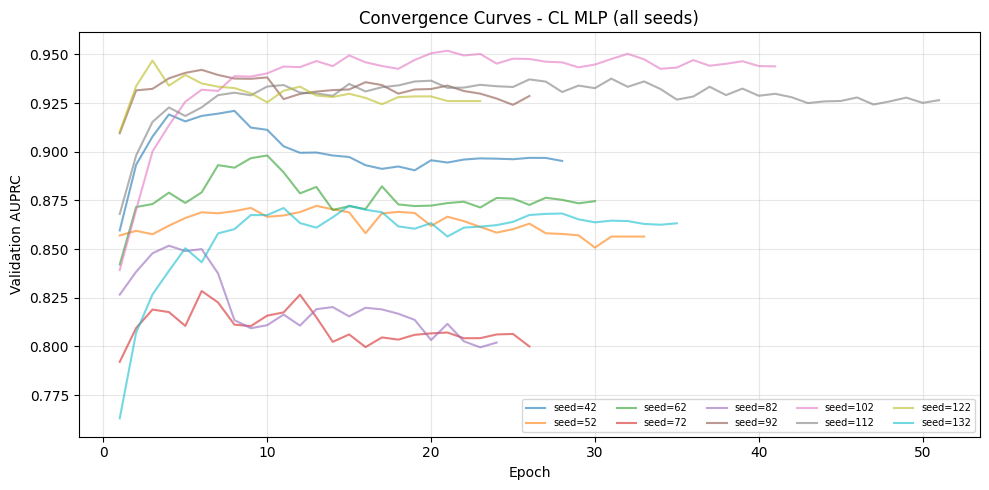

Median epochs to convergence: 29


In [28]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = plt.cm.tab10(np.linspace(0, 1, len(SEEDS)))

for i, seed in enumerate(SEEDS):
    hist = history_by_seed[seed]
    epochs_ = [h["epoch"] for h in hist]
    auprc_  = [h["val_auprc"] if not np.isnan(h["val_auprc"]) else 0
                for h in hist]
    ax.plot(epochs_, auprc_, alpha=0.6, color=colors[i], label=f"seed={seed}")

ax.set_xlabel("Epoch")
ax.set_ylabel("Validation AUPRC")
ax.set_title("Convergence Curves - CL MLP (all seeds)")
ax.legend(fontsize=7, ncol=5)
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig("cl_convergence.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Median epochs to convergence: "
      f"{np.median([len(history_by_seed[s]) for s in SEEDS]):.0f}")


## 15. Final Reporting Table - IEEE Master Summary

This is the master summary table for the centralized notebook. The same metric block is
reproduced for FL in the FL notebook so the two can be placed side-by-side.

The block reports, for every metric:

- **Global** test performance (mean +/- 95 % CI, 10 seeds).
- **Macro per-hospital** (per-seed average across hospitals -> 10-seed CI).
- **Worst-hospital** AUPRC and **disparity gap** (max-min across hospitals).
- **Jain Fairness Index** (AUPRC) - internal diagnostic, not reported in the paper.
- **Probabilistic performance** (Brier).
- **Robustness to unseen hospital** (LOHO macro AUPRC, worst-LOHO AUPRC, LOHO macro
  Brier, and the per-site LOHO Brier range - the last is the reference against which
  the FL-LOHO range is read).
- **Compute** (training time, inference latency).

All seed-level intervals in this table are superseded by the patient-level bootstrap of
Section 8.1 wherever the two overlap.

In [29]:
def fmt(mean, lo, hi):
    return f"{mean:.4f} [{lo:.4f}, {hi:.4f}]"


print("=" * 92)
print("CENTRALIZED LEARNING - IEEE MASTER SUMMARY")
print(f"UCI Heart Disease | 4 Hospitals | MLP | {FINAL_SETTING_LABEL} | n=10 seeds")
print("=" * 92)

# A. Global
print("\n[A] GLOBAL TEST METRICS")
for m in main_metrics:
    mu, lo, hi = ci_95(global_df[m].dropna().values)
    print(f"  {m:11s}: {fmt(mu, lo, hi)}")

# B. Macro per-hospital
print("\n[B] MACRO PER-HOSPITAL METRICS (avg across hospitals, then across seeds)")
for m in ["macro_auroc", "macro_auprc", "macro_f1", "macro_recall", "macro_brier"]:
    mu, lo, hi = ci_95(macro_df[m].values)
    print(f"  {m:14s}: {fmt(mu, lo, hi)}")

# C. Per-hospital row-by-row
print("\n[C] PER-HOSPITAL DETAIL (mean +/- std across 10 seeds)")
for _, r in hosp_summary.iterrows():
    print(f"  {r['hospital']:14s} (n={int(r['n_test'])}): "
          f"AUPRC={r['auprc_mean']:.4f}+/-{r['auprc_std']:.4f}  "
          f"AUROC={r['auroc_mean']:.4f}+/-{r['auroc_std']:.4f}  "
          f"F1={r['f1_mean']:.4f}+/-{r['f1_std']:.4f}  "
          f"Recall={r['recall_mean']:.4f}+/-{r['recall_std']:.4f}")

# D. Worst-hospital + fairness
print("\n[D] WORST-HOSPITAL & FAIRNESS / DISPARITY (AUPRC)")
for k in ["worst_auprc", "best_auprc", "gap_auprc",
          "std_auprc", "cv_auprc", "jfi_auprc"]:
    s = fairness_summary[k]
    print(f"  {k:11s}: {fmt(s['mean'], s['ci_lo'], s['ci_hi'])}")

# E. Calibration
print("\n[E] CALIBRATION")
mu, lo, hi = ci_95(global_df["brier"].values)
print(f"  brier: {fmt(mu, lo, hi)}")

# F. Unseen-hospital robustness (LOHO)
print("\n[F] UNSEEN-HOSPITAL ROBUSTNESS (Leave-One-Hospital-Out)")
for m in ["macro_auroc", "macro_auprc", "macro_f1", "worst_auprc", "gap_auprc"]:
    s = cl_loho_macro_summary[m]
    print(f"  loho_{m:10s}: {fmt(s['mean'], s['ci_lo'], s['ci_hi'])}")
print(f"  per-hospital LOHO:")
print(loho_per_hosp[["held_out", "auprc_mean", "auprc_std", "f1_mean", "n_unseen"]]
.round(4).to_string(index=False))

# G. Compute
print("\n[G] COMPUTE")
print(f"  train_time_s: {global_df['train_time_s'].mean():.1f} +/- "
      f"{global_df['train_time_s'].std(ddof=1):.1f}")
print(f"  infer_per_ms: {global_df['inference_per_sample_ms'].mean():.4f}")
print(f"  n_features: {int(global_df['n_features'].iloc[0])}")
print("=" * 92)


CENTRALIZED LEARNING - IEEE MASTER SUMMARY
UCI Heart Disease | 4 Hospitals | MLP | Setting D | n=10 seeds

[A] GLOBAL TEST METRICS
  auroc      : 0.8989 [0.8937, 0.9041]
  auprc      : 0.9076 [0.9031, 0.9122]
  auprc_lift : 0.3533 [0.3487, 0.3578]
  normalized_auprc: 0.7927 [0.7825, 0.8029]
  f1         : 0.8512 [0.8465, 0.8558]
  recall     : 0.9245 [0.9031, 0.9459]
  specificity: 0.6915 [0.6487, 0.7342]
  balanced_accuracy: 0.8080 [0.7962, 0.8198]
  mcc        : 0.6441 [0.6299, 0.6583]
  precision  : 0.7901 [0.7702, 0.8100]
  accuracy   : 0.8207 [0.8119, 0.8294]
  brier      : 0.1253 [0.1178, 0.1329]

[B] MACRO PER-HOSPITAL METRICS (avg across hospitals, then across seeds)
  macro_auroc   : 0.8014 [0.7854, 0.8173]
  macro_auprc   : 0.8969 [0.8911, 0.9027]
  macro_f1      : 0.8482 [0.8436, 0.8529]
  macro_recall  : 0.9156 [0.8934, 0.9378]
  macro_brier   : 0.1273 [0.1191, 0.1356]

[C] PER-HOSPITAL DETAIL (mean +/- std across 10 seeds)
  Cleveland      (n=61): AUPRC=0.9512+/-0.0081  AU

## 15.1 Repeated External Test Splits - *Split Luck*

The bootstrap in Section 8.1 resamples patients but stays inside the one test partition
drawn at `TEST_SEED = 42`. It cannot tell us whether that particular split was lucky.
Here the entire protocol is rerun end-to-end on several independently drawn external
test splits, and we report the spread of the headline metrics across them.

Any conclusion that survives only on split 42 is not a conclusion.

In [30]:
if RUN_MULTI_SPLIT:
    print(f"Repeated-split evaluation: {len(TEST_SEEDS)} test splits x "
          f"{len(MULTI_SPLIT_SEEDS)} model seeds", flush=True)
    split_rows = []
    for ts in TEST_SEEDS:
        print(f"  test_seed={ts}", end="", flush=True)
        for seed in MULTI_SPLIT_SEEDS:
            print(".", end="", flush=True)
            out = run_single_final(df, seed, test_seed=ts)
            rec = {k: out["global"][k] for k in
                   ["auroc", "auprc", "normalized_auprc", "brier", "f1"]}
            hosp_auprc = [h["auprc"] for h in out["per_hospital"]]
            rec.update({"test_seed": ts, "seed": seed,
                        "macro_auprc": float(np.nanmean(hosp_auprc)),
                        "worst_auprc": float(np.nanmin(hosp_auprc))})
            split_rows.append(rec)
        print()

    split_df = pd.DataFrame(split_rows)
    split_df.to_csv("cl_multi_split_by_run.csv", index=False)

    # Between-split spread: mean within each split, then variation across splits
    per_split = split_df.groupby("test_seed").mean(numeric_only=True)
    print("\nMean per test split")
    print(per_split[["auprc", "macro_auprc", "worst_auprc", "brier"]]
          .round(4).to_string())

    print("\nBetween-split variability (the number the seed-only CI hides)")
    print("-" * 72)
    split_summary = []
    for m in ["auprc", "macro_auprc", "worst_auprc", "brier"]:
        v = per_split[m].values
        rng_ = float(v.max() - v.min())
        mu, lo, hi = ci_95(split_df[m].dropna().values)
        split_summary.append({"metric": m, "mean": float(v.mean()),
                              "sd_across_splits": float(v.std(ddof=1)),
                              "min": float(v.min()), "max": float(v.max()),
                              "range": rng_, "ci_lo": lo, "ci_hi": hi})
        print(f"  {m:12s}: {v.mean():.4f}  sd={v.std(ddof=1):.4f}  "
              f"range=[{v.min():.4f}, {v.max():.4f}]  spread={rng_:.4f}")
    cl_split_summary_df = pd.DataFrame(split_summary)
    cl_split_summary_df.to_csv("cl_multi_split_summary.csv", index=False)
    print("\nSaved: cl_multi_split_by_run.csv, cl_multi_split_summary.csv")
else:
    print("RUN_MULTI_SPLIT = False - skipped.")

Repeated-split evaluation: 5 test splits x 3 model seeds
  test_seed=42...
  test_seed=202...
  test_seed=303...
  test_seed=404...
  test_seed=505...

Mean per test split
            auprc  macro_auprc  worst_auprc   brier
test_seed                                          
42         0.9087       0.8990       0.8019  0.1195
202        0.8951       0.8819       0.7343  0.1396
303        0.9106       0.9171       0.8751  0.1190
404        0.8923       0.8981       0.8150  0.1608
505        0.8737       0.8726       0.7882  0.1269

Between-split variability (the number the seed-only CI hides)
------------------------------------------------------------------------
  auprc       : 0.8961  sd=0.0149  range=[0.8737, 0.9106]  spread=0.0368
  macro_auprc : 0.8937  sd=0.0172  range=[0.8726, 0.9171]  spread=0.0445
  worst_auprc : 0.8029  sd=0.0507  range=[0.7343, 0.8751]  spread=0.1408
  brier       : 0.1332  sd=0.0175  range=[0.1190, 0.1608]  spread=0.0418

Saved: cl_multi_split_by_run.csv, c

In [31]:
# Tidy machine-readable copy of the master summary (CSV-friendly DataFrame) --
def _row(category, metric, mean, ci_lo, ci_hi, std=None):
    return {"category": category, "metric": metric,
            "mean": mean, "ci_lo": ci_lo, "ci_hi": ci_hi, "std": std}


cl_master_rows = []
for m in main_metrics:
    mu, lo, hi = ci_95(global_df[m].dropna().values)
    cl_master_rows.append(_row("global", m, mu, lo, hi, global_df[m].std(ddof=1)))

for m in [c for c in macro_df.columns if c.startswith("macro_")]:
    mu, lo, hi = ci_95(macro_df[m].values)
    cl_master_rows.append(_row("macro_per_hospital", m, mu, lo, hi,
                                macro_df[m].std(ddof=1)))

for fair_metric, summary in fairness_summary_by_metric.items():
    for k, s in summary.items():
        cl_master_rows.append(_row("fairness", k, s["mean"], s["ci_lo"],
                                    s["ci_hi"], s["std"]))

for m in ["macro_auroc", "macro_auprc", "macro_f1", "worst_auprc", "gap_auprc"]:
    s = cl_loho_macro_summary[m]
    cl_master_rows.append(_row("loho_unseen_hospital", m, s["mean"],
                                s["ci_lo"], s["ci_hi"], s["std"]))

if "cl_model_comparison_df" in globals():
    for _, r in cl_model_comparison_df.iterrows():
        cl_master_rows.append(_row(f"model_comparison:{r['model']}",
                                   r["metric"], r["mean"], r["ci_lo"],
                                   r["ci_hi"], r["std"]))


if "cl_small_data_sensitivity_summary_df" in globals():
    for _, r in cl_small_data_sensitivity_summary_df.iterrows():
        cl_master_rows.append(_row(f"small_data_sensitivity:{r['variant']}",
                                   r["metric"], r["mean"], r["ci_lo"],
                                   r["ci_hi"], None))
cl_prediction_rows = []
for seed, out in out_by_seed.items():
    pred = out["df_test"][[HOSPITAL_COL, TARGET_COL]].copy().reset_index(drop=True)
    pred["seed"] = seed
    pred["row_in_fixed_test"] = np.arange(len(pred))
    pred["y_true"] = np.asarray(out["y_test"]).astype(int).ravel()
    pred["y_prob"] = np.asarray(out["y_prob"], dtype=float).ravel()
    cl_prediction_rows.append(pred)
cl_predictions_by_seed_df = pd.concat(cl_prediction_rows, ignore_index=True)

cl_master_df = pd.DataFrame(cl_master_rows)
global_df.to_csv("cl_global_by_seed.csv", index=False)
macro_df.to_csv("cl_macro_by_seed.csv", index=False)
fairness_long.to_csv("cl_fairness_by_seed.csv", index=False)
cl_predictions_by_seed_df.to_csv("cl_predictions_by_seed.csv", index=False)
cl_master_df.to_csv("cl_master_summary.csv", index=False)
print("Saved per-seed CL tables -> cl_global_by_seed.csv, cl_macro_by_seed.csv, cl_fairness_by_seed.csv")
print("Saved per-sample predictions -> cl_predictions_by_seed.csv")
print("Saved master summary table -> cl_master_summary.csv")
if "cl_model_comparison_df" in globals():
    print("Included model comparison rows in master summary and saved cl_model_comparison_summary.csv")
print(cl_master_df.round(4).to_string(index=False))

Saved per-seed CL tables -> cl_global_by_seed.csv, cl_macro_by_seed.csv, cl_fairness_by_seed.csv
Saved per-sample predictions -> cl_predictions_by_seed.csv
Saved master summary table -> cl_master_summary.csv
Included model comparison rows in master summary and saved cl_model_comparison_summary.csv
                             category                  metric   mean  ci_lo  ci_hi    std
                               global                   auroc 0.8989 0.8937 0.9041 0.0073
                               global                   auprc 0.9076 0.9031 0.9122 0.0064
                               global              auprc_lift 0.3533 0.3487 0.3578 0.0064
                               global        normalized_auprc 0.7927 0.7825 0.8029 0.0143
                               global                      f1 0.8512 0.8465 0.8558 0.0065
                               global                  recall 0.9245 0.9031 0.9459 0.0300
                               global             specificity 0.6915 0.

In [32]:
ms = pd.read_csv("fl_master_summary.csv")
 
# Macro AUPRC per (algorithm x dropout) - the fairness-relevant scalar
macro = ms[(ms["section"] == "macro_per_hospital") &
           (ms["metric"] == "macro_auprc")]
glob = ms[(ms["section"] == "global_fl") & (ms["metric"] == "auprc")]
 
def fmt(sub_, algo, d):
    r = sub_[(sub_["algorithm"] == algo) & (sub_["dropout_pct"] == d)]
    if r.empty:
        return "-"
    r = r.iloc[0]
    return f"{r['mean']:.3f} [{r['ci_lo']:.3f}, {r['ci_hi']:.3f}]"
 
algos = ["FEDAVG", "FEDPROX", "FEDADAM"]
 
print("TABLE. CLIENT DROPOUT ROBUSTNESS (MEAN [95% CI], 10 SEEDS)")
print("=" * 78)
print(f"{'Algorithm':11s} {'Dropout':>8s}  {'Macro AUPRC':>22s}  {'Pooled AUPRC':>22s}")
print("-" * 78)
rows = []
for algo in algos:
    for d in [0, 25, 50]:
        m_txt, g_txt = fmt(macro, algo, d), fmt(glob, algo, d)
        print(f"{algo:11s} {str(d) + '%':>8s}  {m_txt:>22s}  {g_txt:>22s}")
        mr = macro[(macro["algorithm"] == algo) & (macro["dropout_pct"] == d)]
        gr = glob[(glob["algorithm"] == algo) & (glob["dropout_pct"] == d)]
        rows.append({
            "algorithm": algo, "dropout_pct": d,
            "macro_auprc": float(mr["mean"].iloc[0]) if not mr.empty else None,
            "macro_ci_lo": float(mr["ci_lo"].iloc[0]) if not mr.empty else None,
            "macro_ci_hi": float(mr["ci_hi"].iloc[0]) if not mr.empty else None,
            "pooled_auprc": float(gr["mean"].iloc[0]) if not gr.empty else None,
            "pooled_ci_lo": float(gr["ci_lo"].iloc[0]) if not gr.empty else None,
            "pooled_ci_hi": float(gr["ci_hi"].iloc[0]) if not gr.empty else None})
    print()
 
drop_df = pd.DataFrame(rows)
drop_df.to_csv("fl_dropout_table.csv", index=False)
 
# Change relative to 0%, so the text can quote a number instead of "no change"
print("Change in macro AUPRC relative to 0% dropout")
print("-" * 78)
for algo in algos:
    base = drop_df[(drop_df.algorithm == algo) & (drop_df.dropout_pct == 0)]
    if base.empty or base["macro_auprc"].isna().all():
        continue
    b = float(base["macro_auprc"].iloc[0])
    parts = []
    for d in [25, 50]:
        r = drop_df[(drop_df.algorithm == algo) & (drop_df.dropout_pct == d)]
        if not r.empty and pd.notna(r["macro_auprc"].iloc[0]):
            parts.append(f"{d}%: {float(r['macro_auprc'].iloc[0]) - b:+.4f}")
    print(f"  {algo:10s} " + "   ".join(parts))
 
print("\nAll intervals overlap the 0% interval for every algorithm; the largest")
print("shift is far smaller than the per-hospital bootstrap widths reported")
print("earlier, so this is an absence of evidence, not evidence of robustness.")
print("\nSaved: fl_dropout_table.csv")

TABLE. CLIENT DROPOUT ROBUSTNESS (MEAN [95% CI], 10 SEEDS)
Algorithm    Dropout             Macro AUPRC            Pooled AUPRC
------------------------------------------------------------------------------
FEDAVG            0%    0.892 [0.881, 0.902]    0.883 [0.871, 0.896]
FEDAVG           25%    0.891 [0.881, 0.902]    0.885 [0.870, 0.900]
FEDAVG           50%    0.884 [0.865, 0.904]    0.873 [0.846, 0.901]

FEDPROX           0%    0.881 [0.871, 0.891]    0.872 [0.858, 0.886]
FEDPROX          25%    0.881 [0.872, 0.891]    0.873 [0.858, 0.888]
FEDPROX          50%    0.884 [0.875, 0.894]    0.873 [0.858, 0.888]

FEDADAM           0%    0.891 [0.872, 0.910]    0.883 [0.861, 0.905]
FEDADAM          25%    0.893 [0.885, 0.901]    0.884 [0.871, 0.897]
FEDADAM          50%    0.893 [0.885, 0.902]    0.886 [0.873, 0.899]

Change in macro AUPRC relative to 0% dropout
------------------------------------------------------------------------------
  FEDAVG     25%: -0.0002   50%: -0.0074
  FE

### 15.2 Reading the Master Table for the Paper

- Section **[A]** is what most papers report as "the result". Here it is one evidence
  block among several, and its seed-level intervals are superseded by the patient-level
  bootstrap in Section 8.1.
- Sections **[B]-[D]** are the per-site disparity diagnostics. Worst-hospital AUPRC is
  carried into the paper; disparity gap and JFI are internal only. No pairwise
  difference in worst-hospital AUPRC is resolvable once patients are resampled.
- Section **[F]** is the unseen-hospital block. The headline there is the centralized
  LOHO Brier range (0.158-0.179), which is the reference against which the FL-LOHO
  range (0.143-0.398) is read.

The FL notebook contains a structurally identical block, so a side-by-side CL-vs-FL
table falls out of merging the two `*_master_summary.csv` files.